# Notebook 06 — Temporal Analysis
**Projet : Predictive Maintenance – MetroPT-3**

## Objectif
Étudier l'évolution temporelle des signaux du compresseur avant, pendant et après les quatre événements documentés.

Ce notebook complète les analyses des notebooks précédents. Il ne refait pas le contrôle qualité, l'analyse univariée ni les corrélations déjà réalisées.

**Questions principales**
1. Les signaux évoluent-ils avant le début d'un événement ?
2. Leur comportement change-t-il pendant l'événement ?
3. Reviennent-ils à leur niveau précédent après l'événement ?
4. Les comportements sont-ils similaires entre les quatre événements ?
5. Quelle dépendance temporelle faut-il prendre en compte pour le feature engineering et la validation ?

> Important : une variation observée avant un événement ne constitue pas automatiquement un signal prédictif. Les conclusions doivent être vérifiées sur les résultats réels.

## 0. Organisation

1. Chargement et préparation temporelle
2. Vue temporelle globale
3. Analyse par événement
4. Comparaison avant / pendant / après
5. Statistiques glissantes et variations
6. Comparaison entre événements
7. Autocorrélation
8. Synthèse et implications pour le Machine Learning

## 1. Imports et configuration

Les chemins doivent correspondre à l'organisation réelle du dépôt. Renseigner `DATA_PATH` avec le fichier labellisé issu du Notebook 02.

Les intervalles des événements ci-dessous reprennent ceux utilisés pour construire `target_event`. Si `config.yaml` contient déjà ces intervalles, conserver une seule source de vérité et charger les événements depuis la configuration.

In [10]:
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

with open("../config.yaml", "r", encoding="utf-8") as fichier:
    config = yaml.safe_load(fichier)

chemin_dataset = (
    Path("../")
    / config["data"]["processed_path"]
    / config["data"]["processed_dataset_name"]
)

# Dossier de sauvegarde des figures.
FIGURES_DIR = Path("reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Fenêtres d'analyse autour des événements.
WINDOW_BEFORE = pd.Timedelta(hours=24)
WINDOW_AFTER = pd.Timedelta(hours=24)

## 2. Chargement et préparation temporelle

On vérifie uniquement les éléments indispensables à cette analyse : présence des colonnes, conversion des timestamps et ordre chronologique. Le contrôle qualité complet a déjà été effectué dans le Notebook 01.

In [11]:
if not chemin_dataset.exists():
    raise FileNotFoundError(
        f"Dataset introuvable : {chemin_dataset.resolve()}\n"
        "Modifie DATA_PATH pour pointer vers le fichier labellisé du Notebook 02."
    )

df = pd.read_csv(chemin_dataset)

required_columns = ["timestamp", "target_event", "event_id"]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Colonnes obligatoires manquantes : {missing_columns}")

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

if df["timestamp"].isna().any():
    raise ValueError("Des timestamps invalides sont présents.")

df = df.sort_values("timestamp").reset_index(drop=True)
df = df.set_index("timestamp")

if not df.index.is_monotonic_increasing:
    raise ValueError("Les données ne sont pas triées chronologiquement.")

print("Dimensions :", df.shape)
print("Période :", df.index.min(), "→", df.index.max())
print("Fréquence médiane (secondes) :",
      df.index.to_series().diff().dt.total_seconds().median())
display(df.head())

Dimensions : (1516948, 18)
Période : 2020-02-01 00:00:00 → 2020-09-01 03:59:50
Fréquence médiane (secondes) : 10.0


,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses,target_event,event_id
timestamp,,,,,,,,,,,,,,,,,,
2020-02-01 00:00:00,0,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:10,10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:19,20,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:29,30,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN
2020-02-01 00:00:39,40,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0,NaN


### 2.1. Variables étudiées

Les listes reprennent les variables documentées et retenues dans les analyses précédentes. Les colonnes de cible et d'identification d'événement ne sont jamais utilisées comme variables capteurs.

In [12]:
numeric_features = [
    "TP2", "TP3", "H1", "DV_pressure",
    "Reservoirs", "Oil_temperature", "Motor_current"
]

digital_features = [
    "COMP", "DV_eletric", "Towers", "MPG",
    "LPS", "Pressure_switch", "Oil_level",
    "Caudal_impulses"
]

features = numeric_features + digital_features
missing_features = [c for c in features if c not in df.columns]

if missing_features:
    raise ValueError(f"Variables capteurs manquantes : {missing_features}")

print(f"{len(numeric_features)} variables numériques")
print(f"{len(digital_features)} variables digitales")

7 variables numériques
8 variables digitales


### 2.2. Définition des événements documentés

Les bornes sont inclusives, comme dans la construction de la cible du Notebook 02. Vérifier que ces dates sont strictement identiques à celles de `config.yaml` et du Notebook 02.

In [13]:
events = {
    "event_1": {
        "start": pd.Timestamp("2020-04-18 00:00:00"),
        "end": pd.Timestamp("2020-04-18 23:59:00"),
    },
    "event_2": {
        "start": pd.Timestamp("2020-05-29 23:30:00"),
        "end": pd.Timestamp("2020-05-30 06:00:00"),
    },
    "event_3": {
        "start": pd.Timestamp("2020-06-05 10:00:00"),
        "end": pd.Timestamp("2020-06-07 14:30:00"),
    },
    "event_4": {
        "start": pd.Timestamp("2020-07-15 14:30:00"),
        "end": pd.Timestamp("2020-07-15 19:00:00"),
    },
}

for name, event in events.items():
    if event["start"] > event["end"]:
        raise ValueError(f"Bornes invalides pour {name}")

In [14]:
# Contrôle de cohérence entre les intervalles documentés et target_event.
event_check = []

for event_name, event in events.items():
    mask = (df.index >= event["start"]) & (df.index <= event["end"])
    target_in_window = df.loc[mask, "target_event"]

    event_check.append({
        "event": event_name,
        "start": event["start"],
        "end": event["end"],
        "rows_in_window": len(target_in_window),
        "positive_rows": int(target_in_window.sum()),
        "target_positive_rate": target_in_window.mean()
    })

event_check = pd.DataFrame(event_check)
display(event_check)

,event,start,end,rows_in_window,positive_rows,target_positive_rate
0,event_1,2020-04-18 00:00:00,2020-04-18 23:59:00,8657,8657,1.0
1,event_2,2020-05-29 23:30:00,2020-05-30 06:00:00,2360,2360,1.0
2,event_3,2020-06-05 10:00:00,2020-06-07 14:30:00,17315,17315,1.0
3,event_4,2020-07-15 14:30:00,2020-07-15 19:00:00,1622,1622,1.0


## 3. Vue temporelle globale

L'agrégation journalière facilite la lecture de l'évolution globale sans tracer les 1,5 million de lignes sur chaque graphique.

- Variables numériques : médiane journalière.
- Variables digitales : proportion journalière de valeurs actives.
- Cible : nombre d'observations positives par jour.

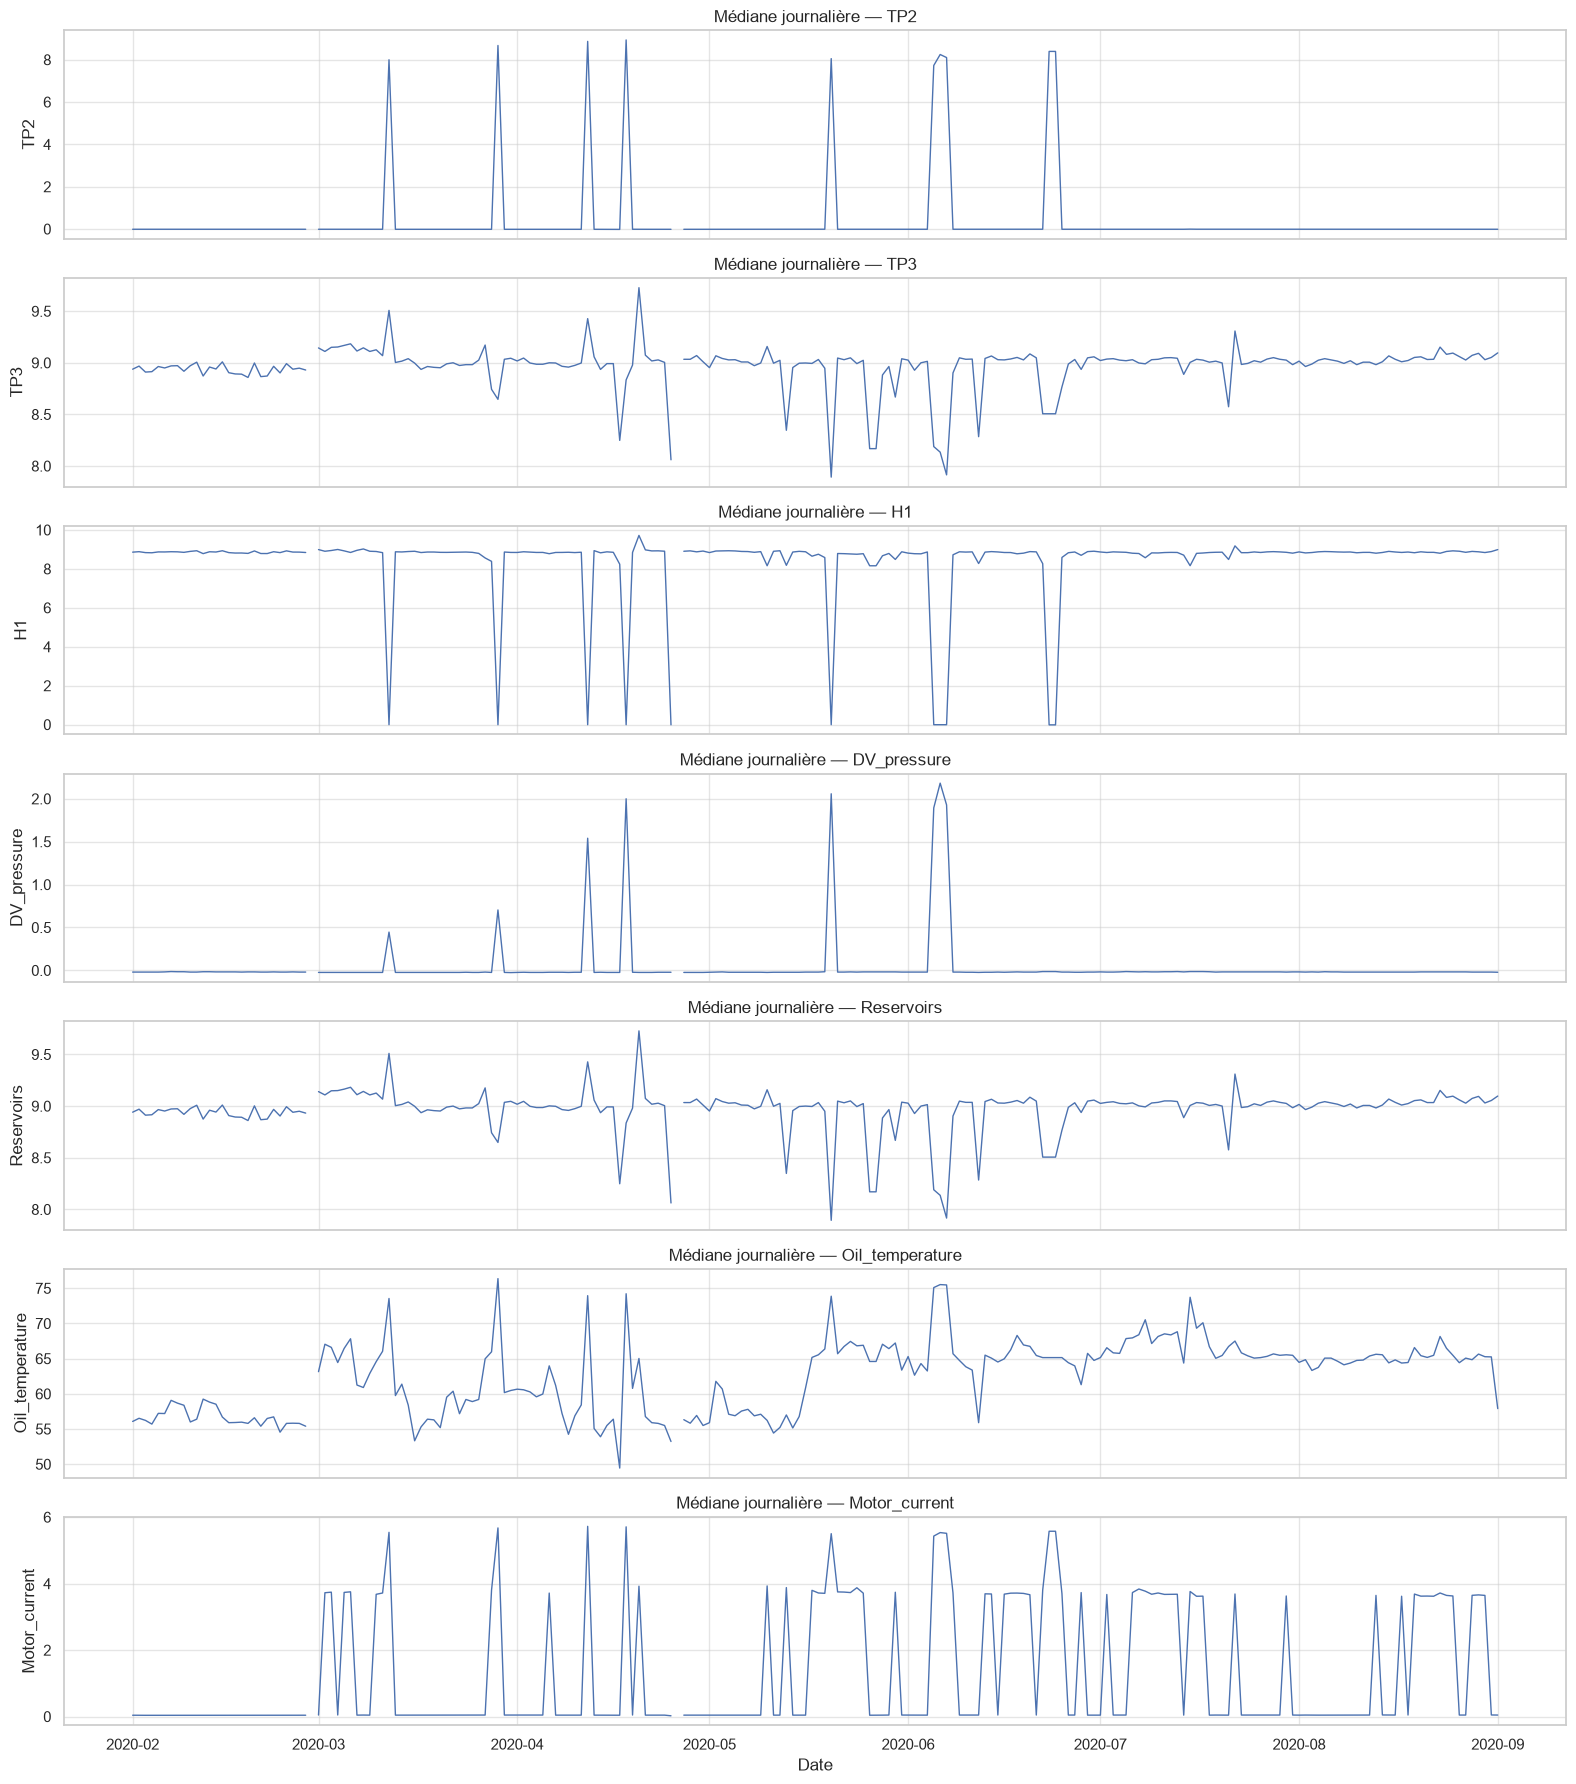

In [15]:
daily_numeric = df[numeric_features].resample("1D").median()

fig, axes = plt.subplots(
    len(numeric_features), 1,
    figsize=(16, 18), sharex=True
)

for ax, col in zip(axes, numeric_features):
    ax.plot(daily_numeric.index, daily_numeric[col], linewidth=1)
    ax.set_title(f"Médiane journalière — {col}")
    ax.set_ylabel(col)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

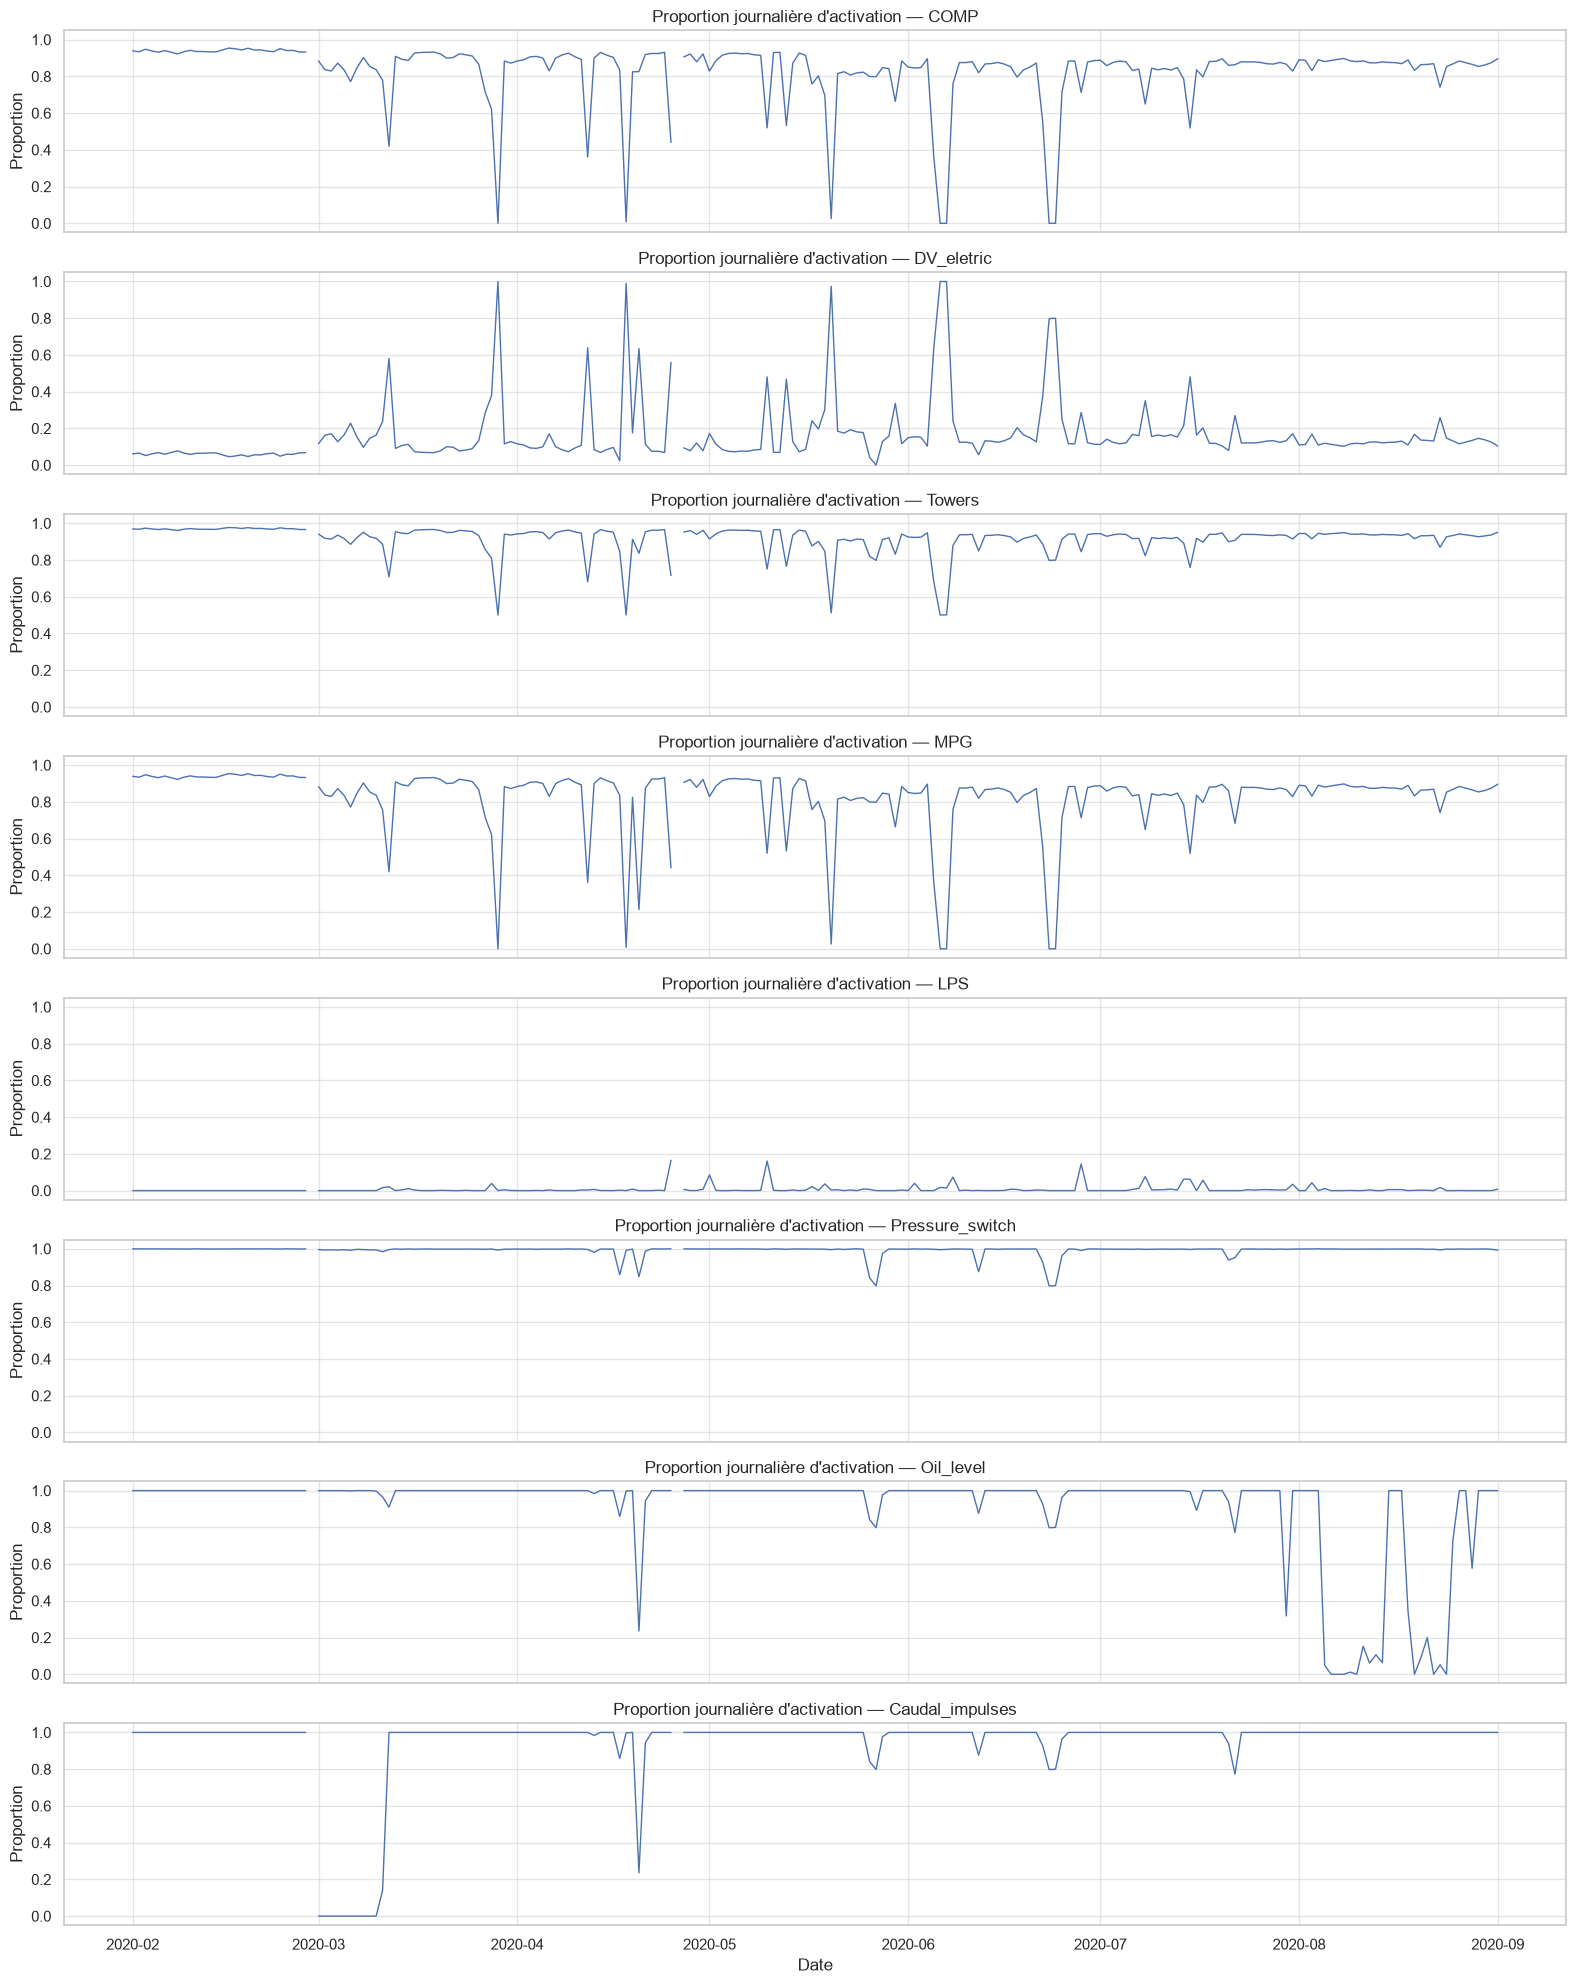

In [16]:
daily_digital = df[digital_features].resample("1D").mean()

fig, axes = plt.subplots(
    len(digital_features), 1,
    figsize=(16, 20), sharex=True
)

for ax, col in zip(axes, digital_features):
    ax.plot(daily_digital.index, daily_digital[col], linewidth=1)
    ax.set_title(f"Proportion journalière d'activation — {col}")
    ax.set_ylabel("Proportion")
    ax.set_ylim(-0.05, 1.05)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

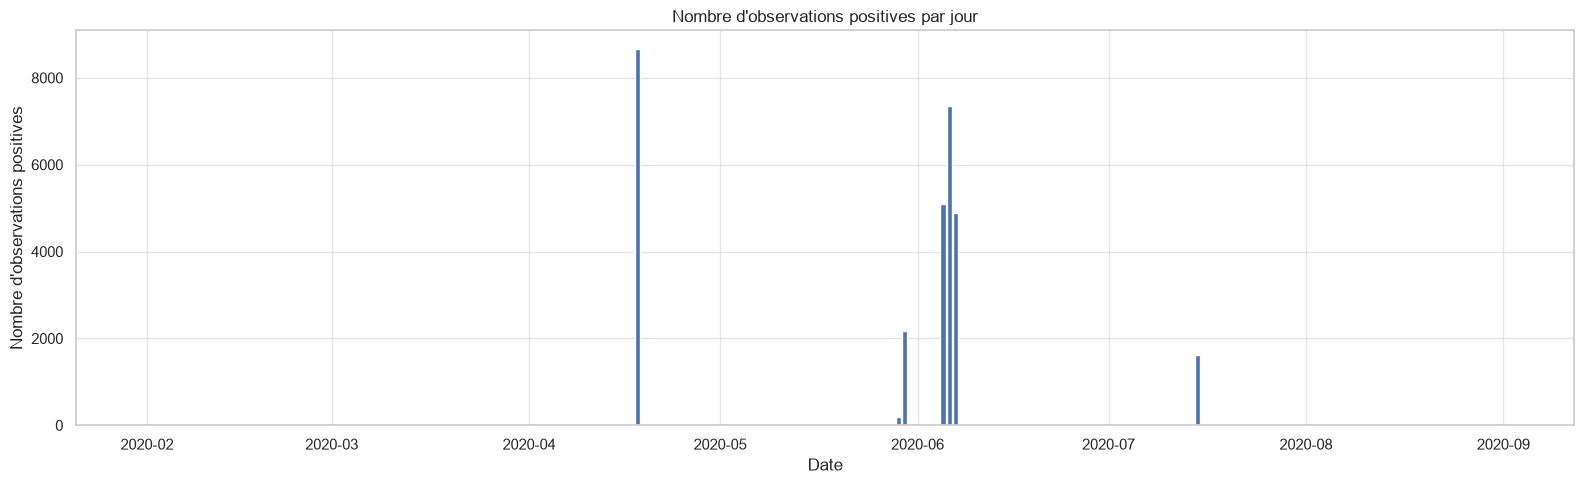

,positive_count,observation_count,positive_rate
timestamp,,,
2020-02-01,0,7144,0.0
2020-02-02,0,7031,0.0
2020-02-03,0,8716,0.0
2020-02-04,0,8717,0.0
2020-02-05,0,7437,0.0


In [17]:
daily_target = df["target_event"].resample("1D").agg(
    positive_count="sum",
    observation_count="count",
    positive_rate="mean"
)

fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(daily_target.index, daily_target["positive_count"], width=0.8)
ax.set_title("Nombre d'observations positives par jour")
ax.set_xlabel("Date")
ax.set_ylabel("Nombre d'observations positives")
plt.tight_layout()
plt.show()

display(daily_target.head())

## 4. Analyse temporelle par événement

Chaque événement est visualisé avec une fenêtre de 24 heures avant son début et de 24 heures après sa fin. La zone rouge représente l'intervalle documenté de l'événement.

In [18]:
event_windows = {}

for event_name, event in events.items():
    window_start = event["start"] - WINDOW_BEFORE
    window_end = event["end"] + WINDOW_AFTER

    event_windows[event_name] = df.loc[
        (df.index >= window_start) & (df.index <= window_end)
    ].copy()

    print(event_name, ":", len(event_windows[event_name]), "observations")

event_1 : 23513 observations
event_2 : 17082 observations
event_3 : 26813 observations
event_4 : 16407 observations


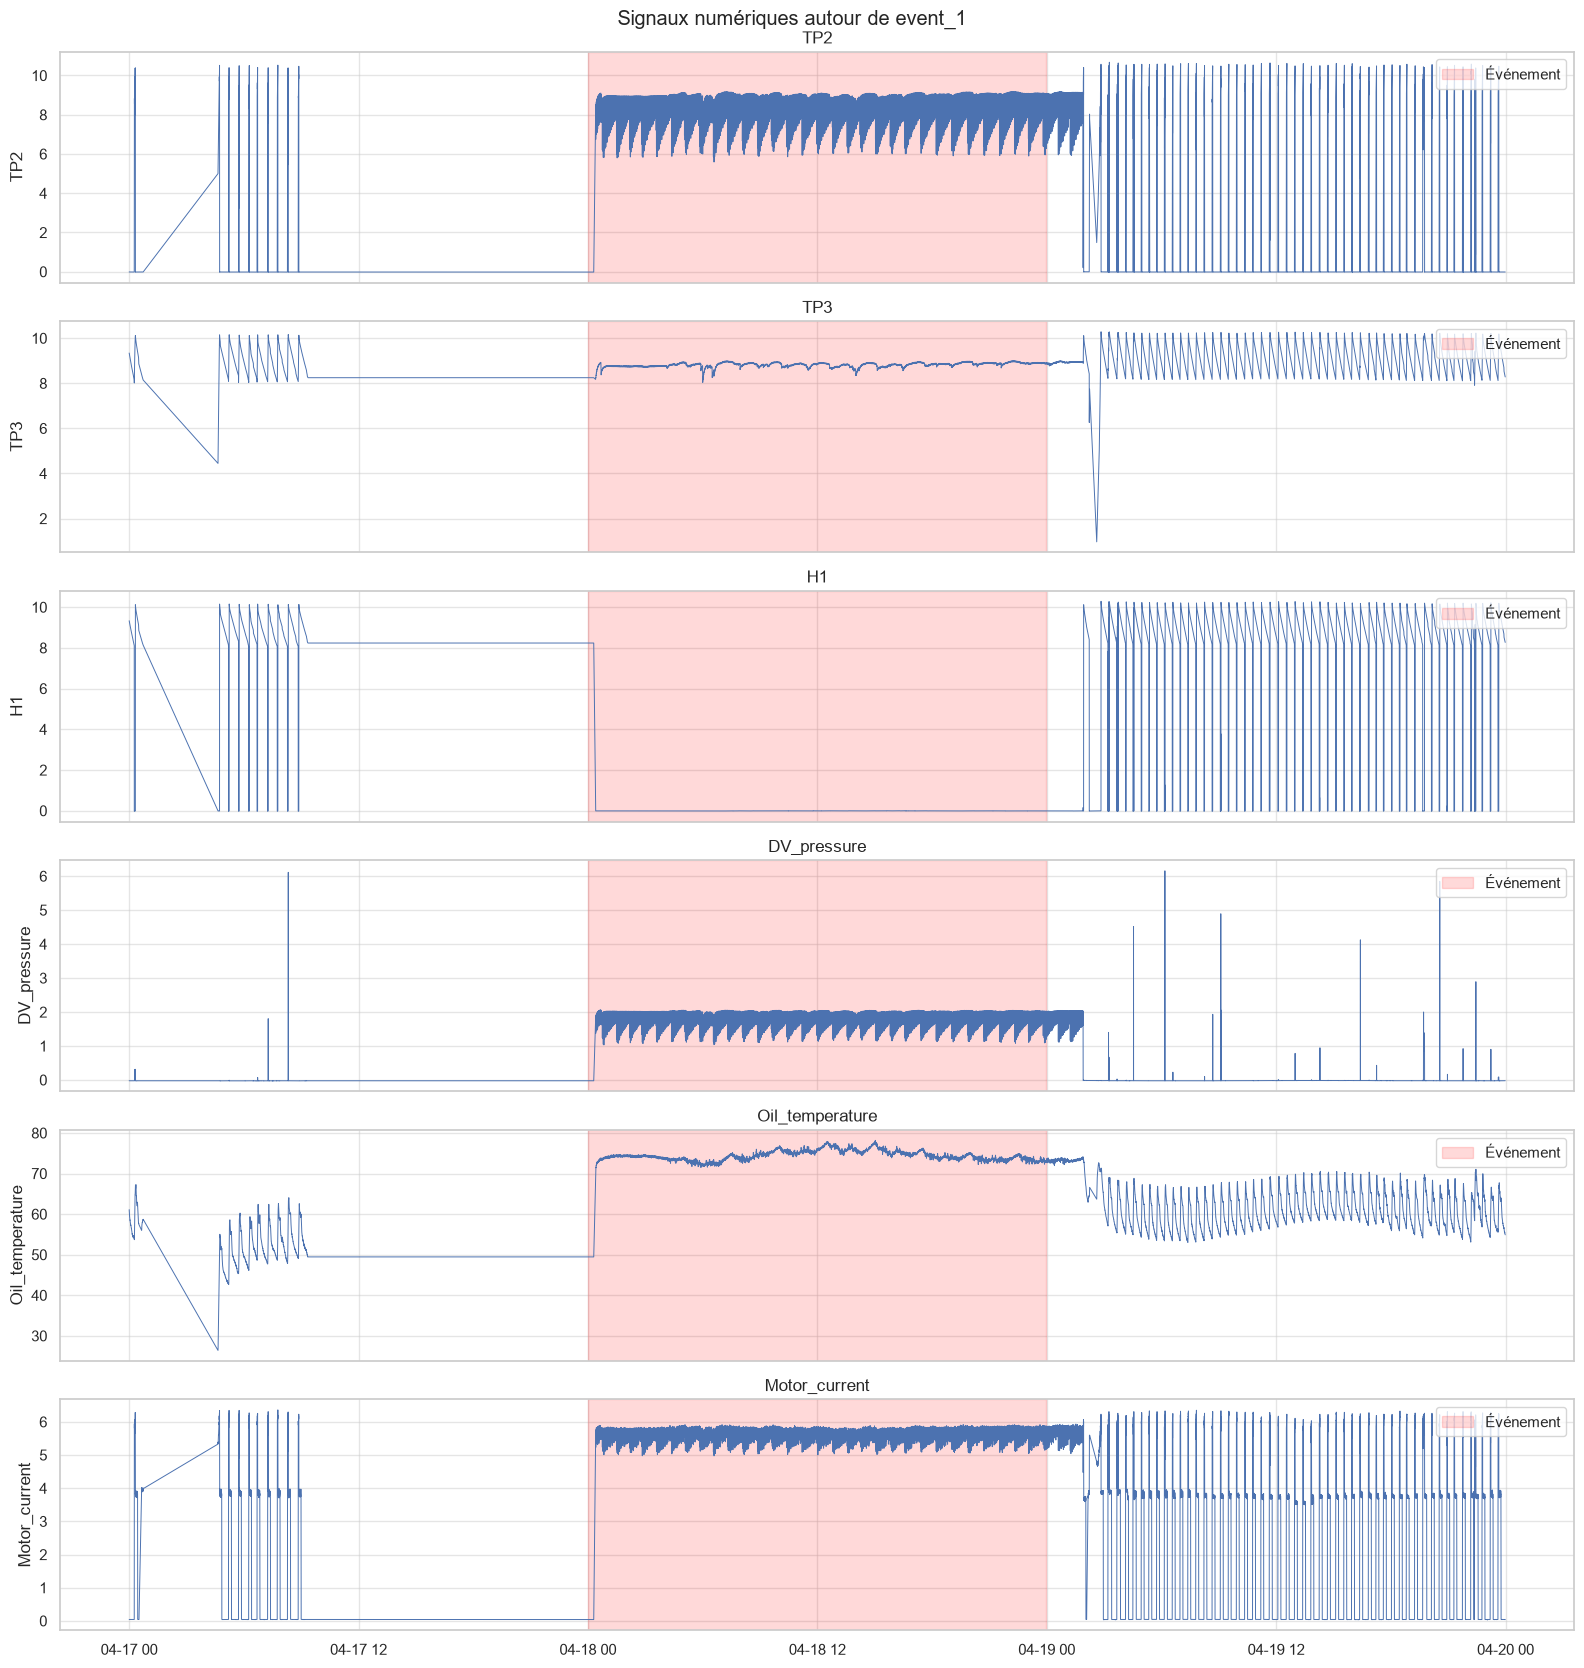

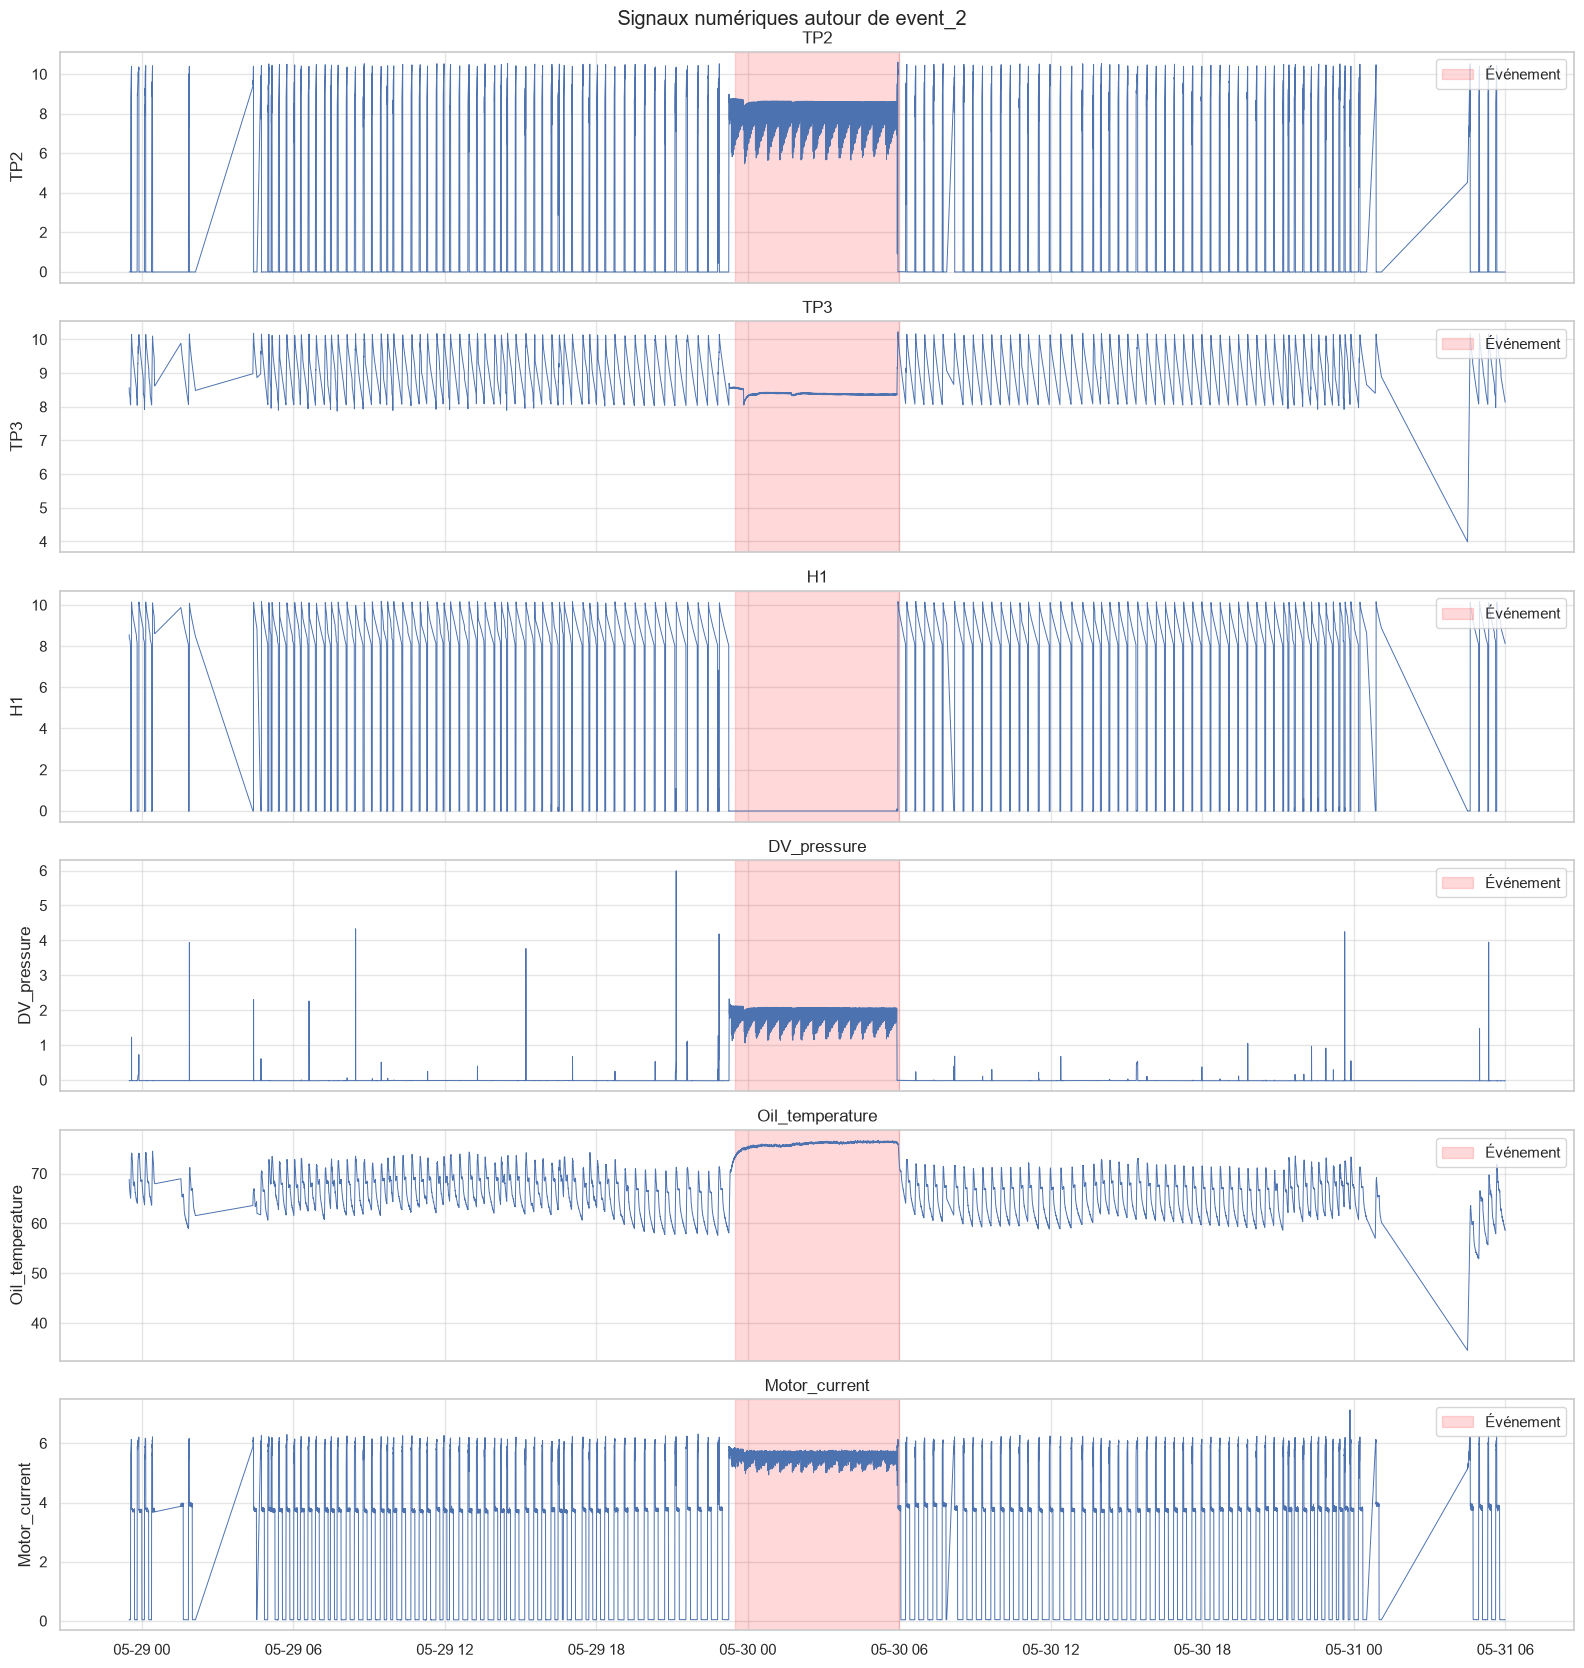

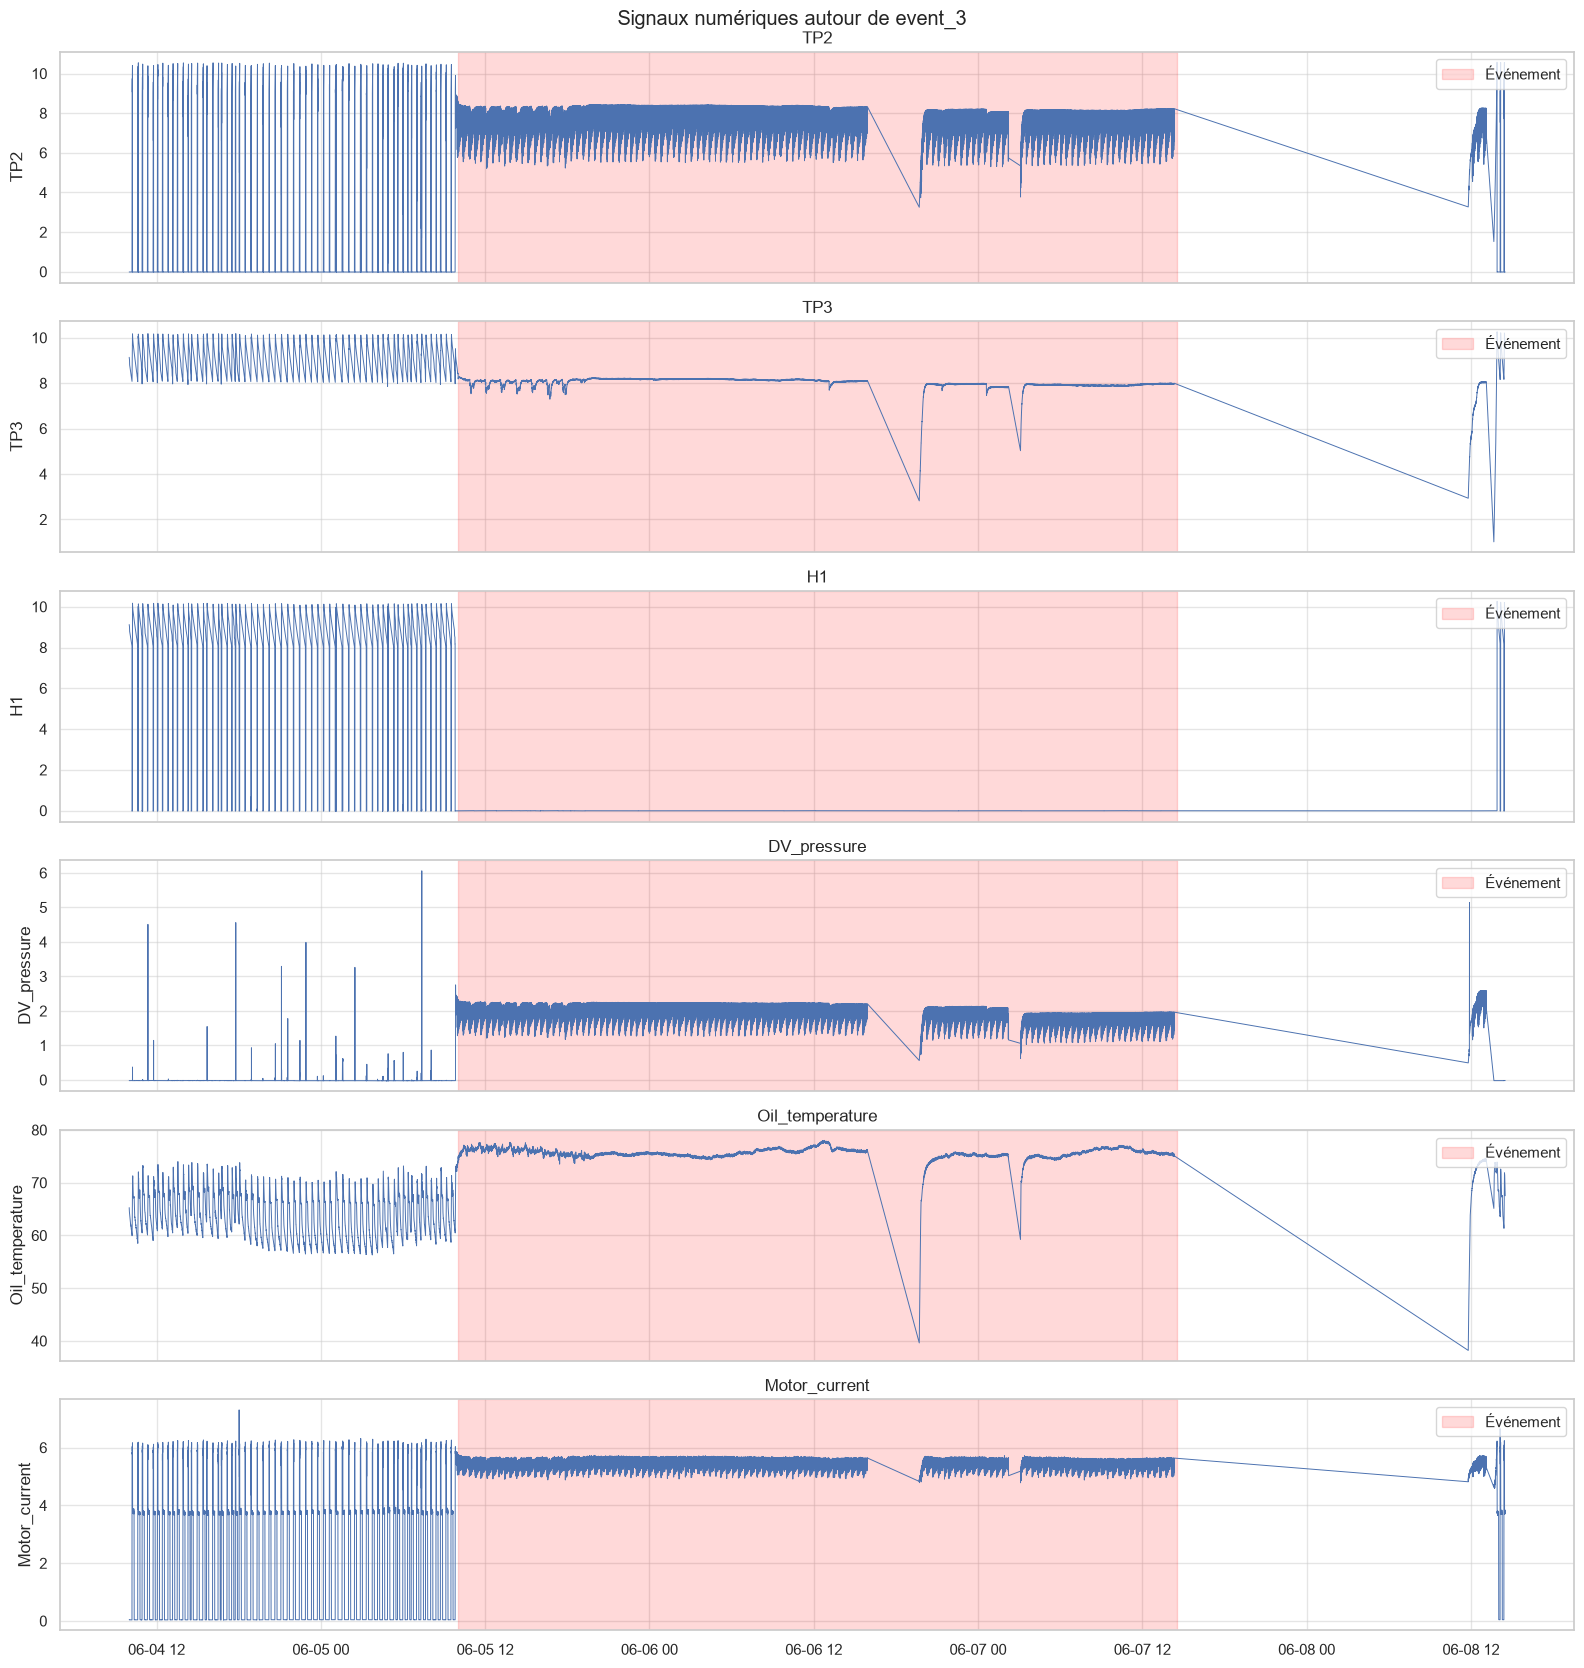

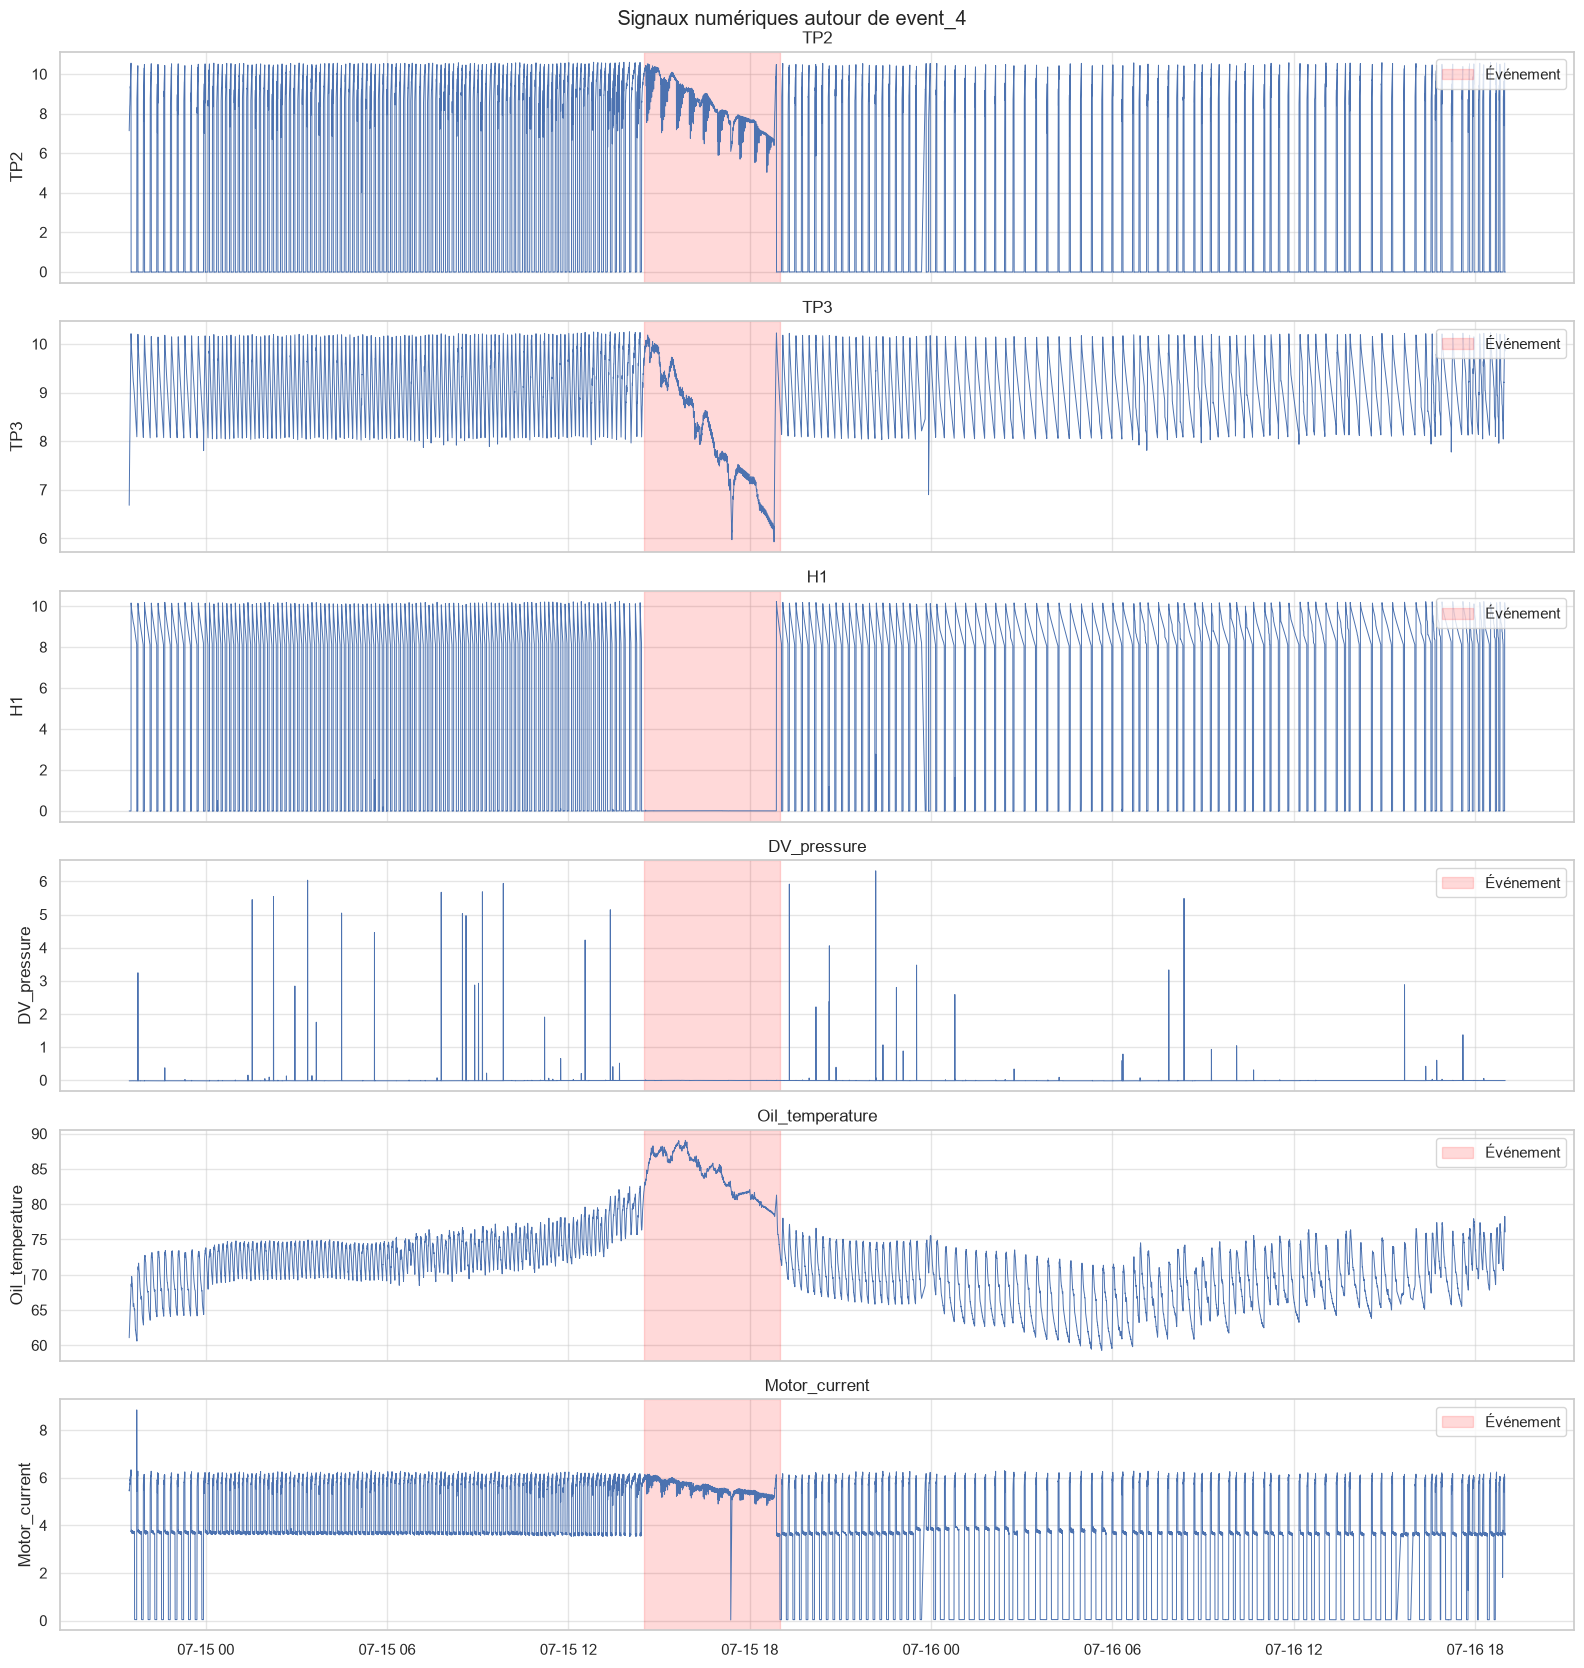

In [19]:
selected_numeric = [
    "TP2", "TP3", "H1", "DV_pressure",
    "Oil_temperature", "Motor_current"
]

for event_name, event in events.items():
    data = event_windows[event_name]

    fig, axes = plt.subplots(
        len(selected_numeric), 1,
        figsize=(16, 17), sharex=True
    )

    for ax, col in zip(axes, selected_numeric):
        ax.plot(data.index, data[col], linewidth=0.7)
        ax.axvspan(event["start"], event["end"],
                   color="red", alpha=0.15, label="Événement")
        ax.set_title(col)
        ax.set_ylabel(col)
        ax.legend(loc="upper right")

    fig.suptitle(f"Signaux numériques autour de {event_name}")
    plt.tight_layout()
    plt.show()

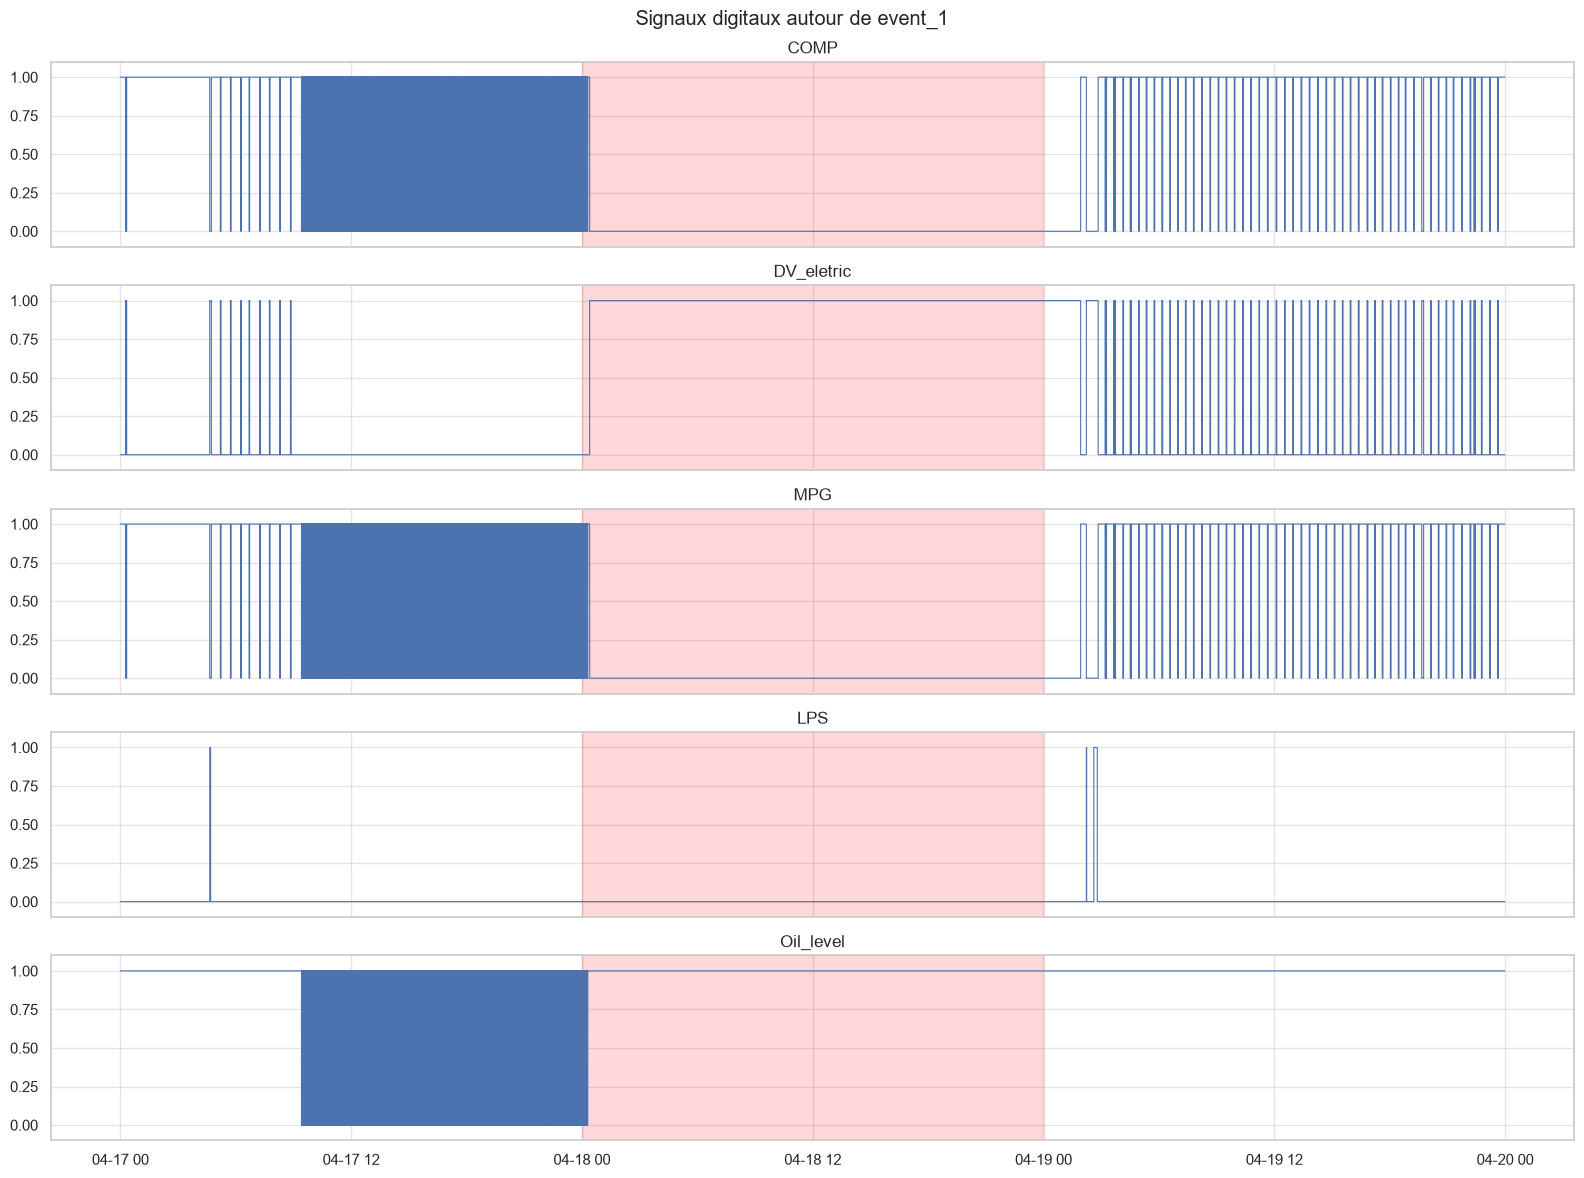

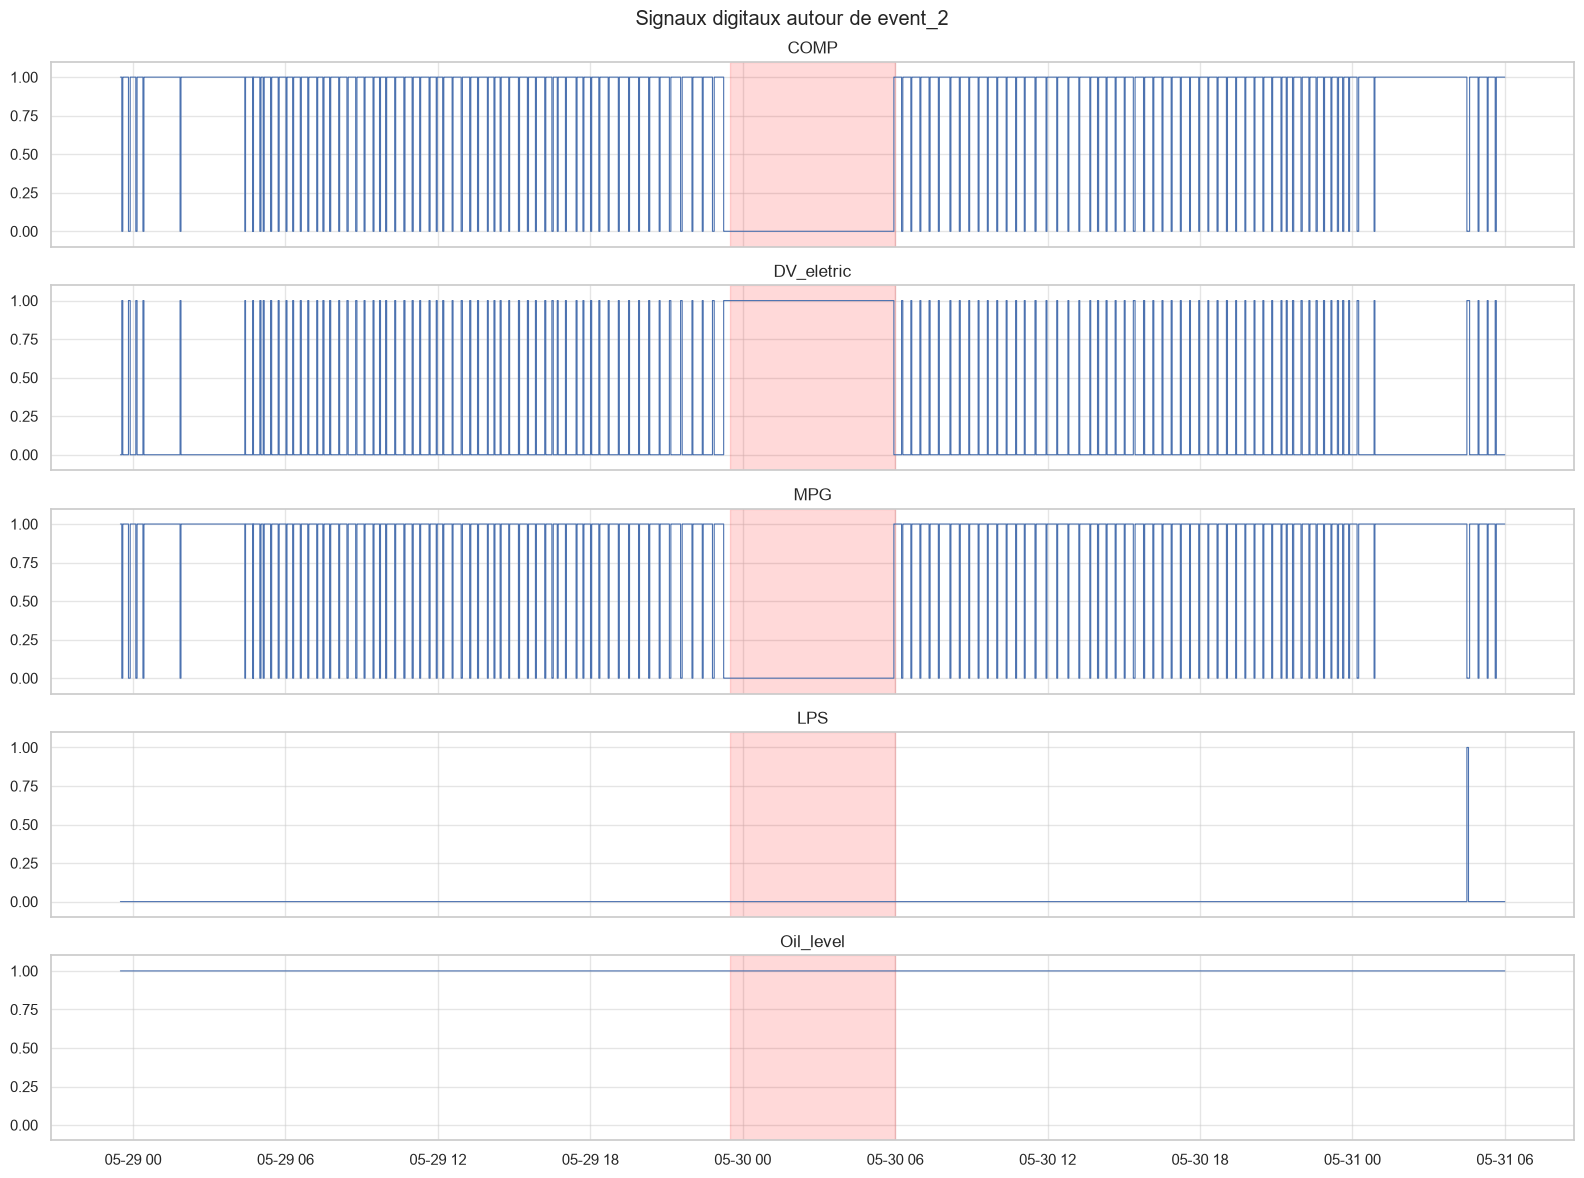

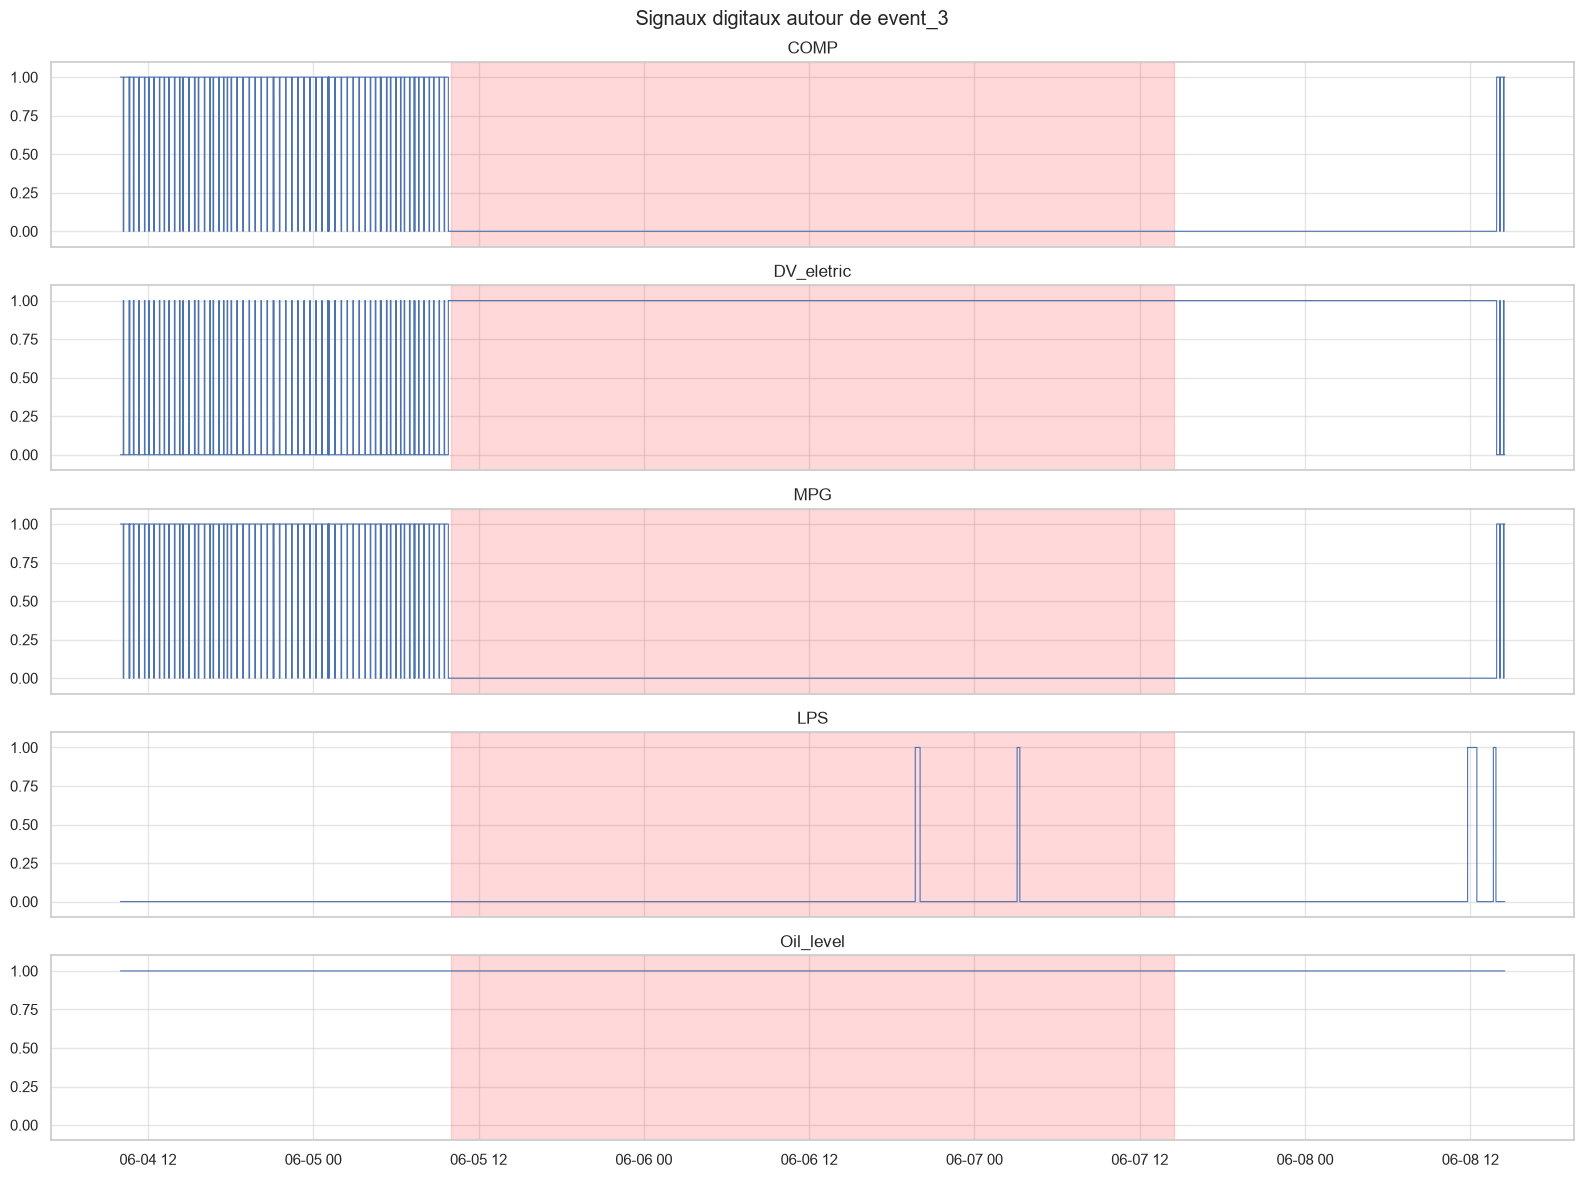

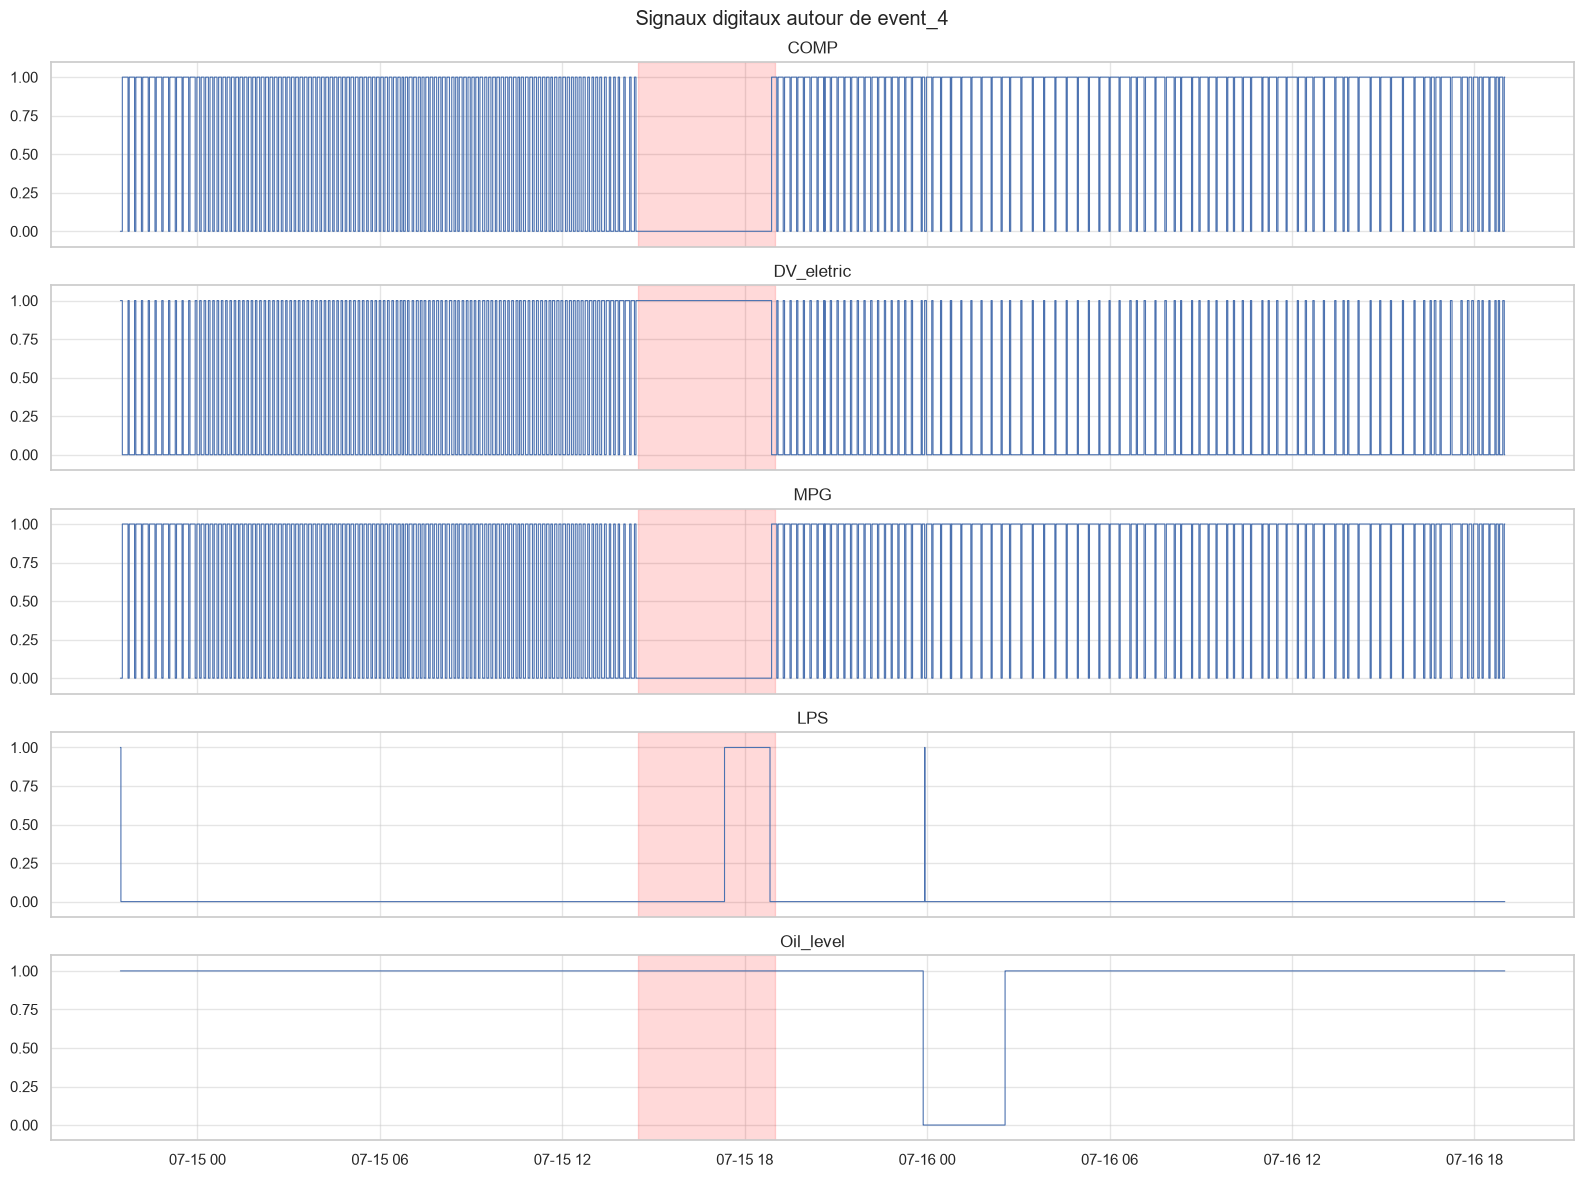

In [20]:
selected_digital = ["COMP", "DV_eletric", "MPG", "LPS", "Oil_level"]

for event_name, event in events.items():
    data = event_windows[event_name]

    fig, axes = plt.subplots(
        len(selected_digital), 1,
        figsize=(16, 12), sharex=True
    )

    for ax, col in zip(axes, selected_digital):
        ax.step(data.index, data[col], where="post", linewidth=0.8)
        ax.axvspan(event["start"], event["end"],
                   color="red", alpha=0.15)
        ax.set_title(col)
        ax.set_ylim(-0.1, 1.1)

    fig.suptitle(f"Signaux digitaux autour de {event_name}")
    plt.tight_layout()
    plt.show()

## 5. Comparaison avant / pendant / après les événements

Définition des phases :
- **before** : les 24 heures précédant le début de l'événement ;
- **during** : l'intervalle documenté de l'événement ;
- **after** : les 24 heures suivant la fin de l'événement.

Les bornes sont choisies pour éviter de compter deux fois les observations de frontière.

In [21]:
def extract_event_phases(data, event):
    start, end = event["start"], event["end"]

    before = data.loc[
        (data.index >= start - WINDOW_BEFORE) & (data.index < start)
    ]
    during = data.loc[
        (data.index >= start) & (data.index <= end)
    ]
    after = data.loc[
        (data.index > end) & (data.index <= end + WINDOW_AFTER)
    ]

    return {"before": before, "during": during, "after": after}

In [22]:
phase_results = []

for event_name, event in events.items():
    phases = extract_event_phases(df, event)

    for phase_name, phase_data in phases.items():
        for col in numeric_features:
            values = phase_data[col].dropna()

            if values.empty:
                continue

            phase_results.append({
                "event": event_name,
                "phase": phase_name,
                "feature": col,
                "count": len(values),
                "mean": values.mean(),
                "median": values.median(),
                "std": values.std(),
                "min": values.min(),
                "max": values.max()
            })

phase_stats = pd.DataFrame(phase_results)
display(phase_stats)

,event,phase,feature,count,mean,median,std,min,max
0,event_1,before,TP2,6301,0.194092,-0.018,1.373245,-0.030,10.5280
1,event_1,before,TP3,6301,8.468162,8.248,0.479627,4.446,10.1620
2,event_1,before,H1,6301,8.247850,8.238,1.363467,-0.032,10.1560
3,event_1,before,DV_pressure,6301,-0.022322,-0.024,0.081955,-0.028,6.1120
4,event_1,before,Reservoirs,6301,8.468139,8.248,0.479377,4.438,10.1620
...,...,...,...,...,...,...,...,...,...
79,event_4,after,H1,8600,7.650005,8.813,3.281463,-0.028,10.2260
80,event_4,after,DV_pressure,8600,-0.008622,-0.014,0.147422,-0.022,6.3180
81,event_4,after,Reservoirs,8600,9.048445,9.030,0.591535,6.902,10.2300
82,event_4,after,Oil_temperature,8600,68.823328,68.925,3.928375,59.275,78.2750


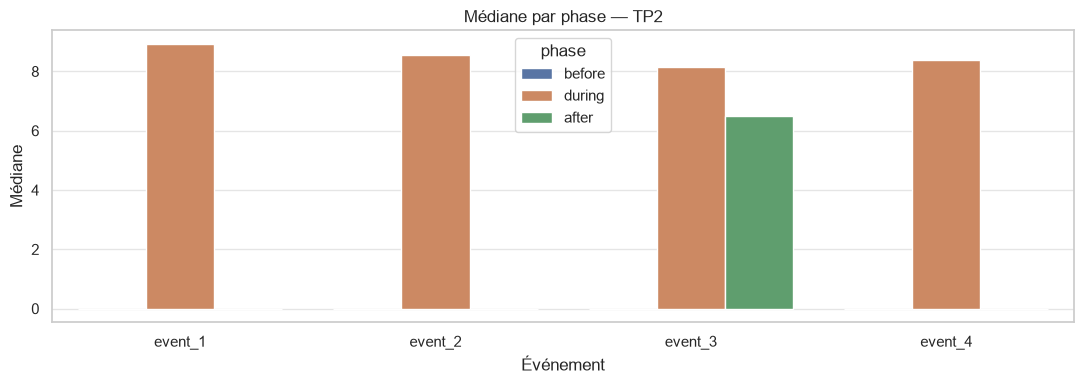

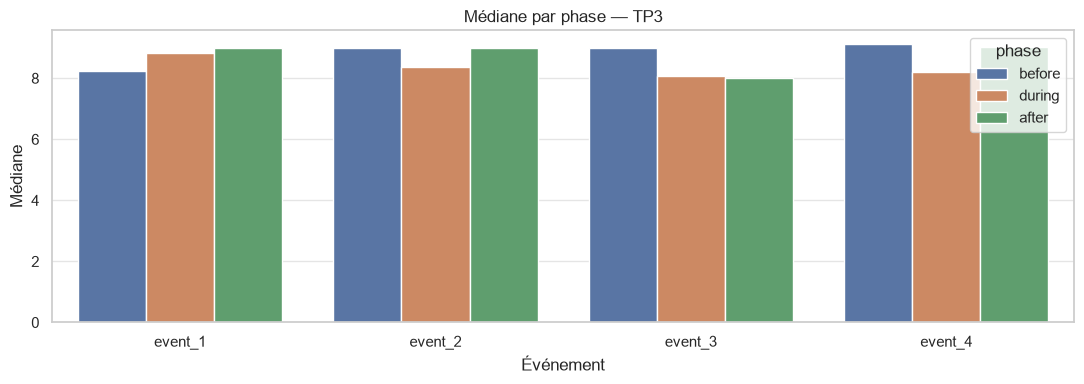

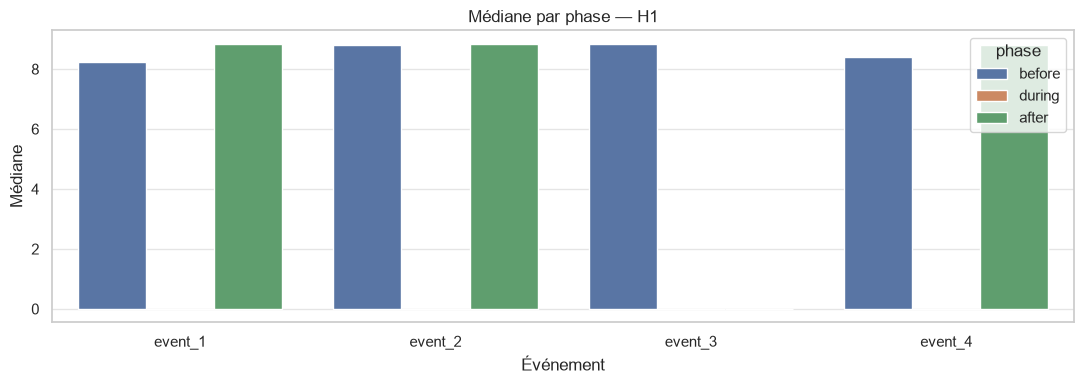

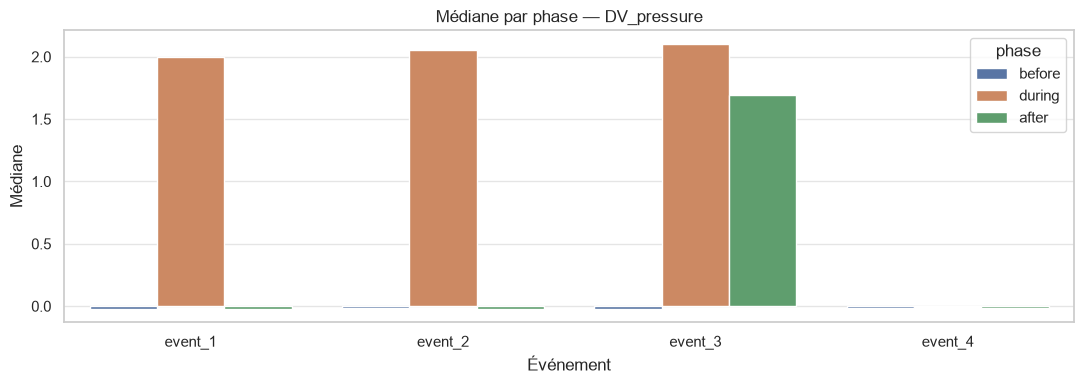

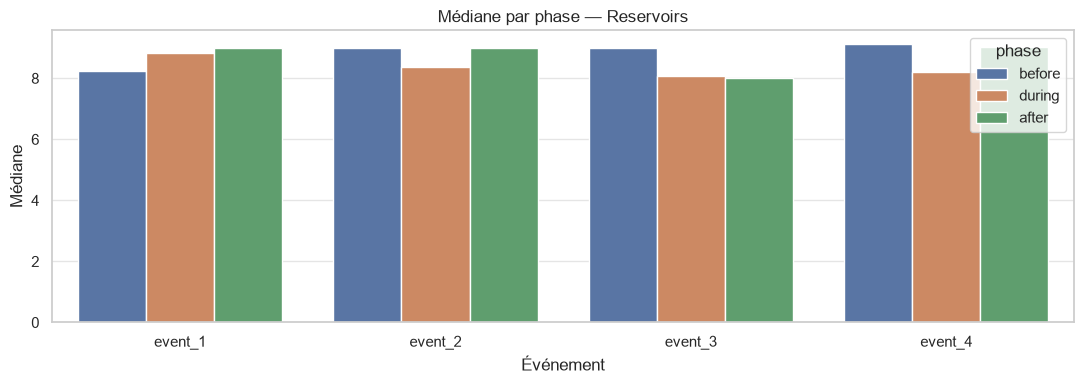

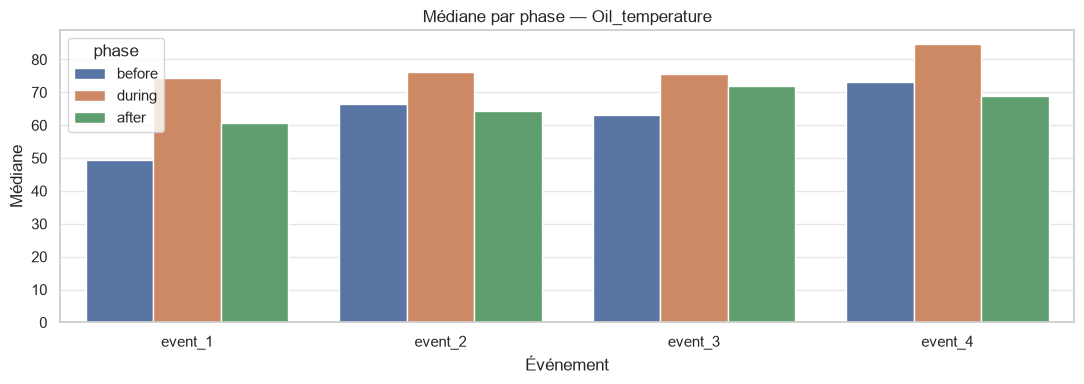

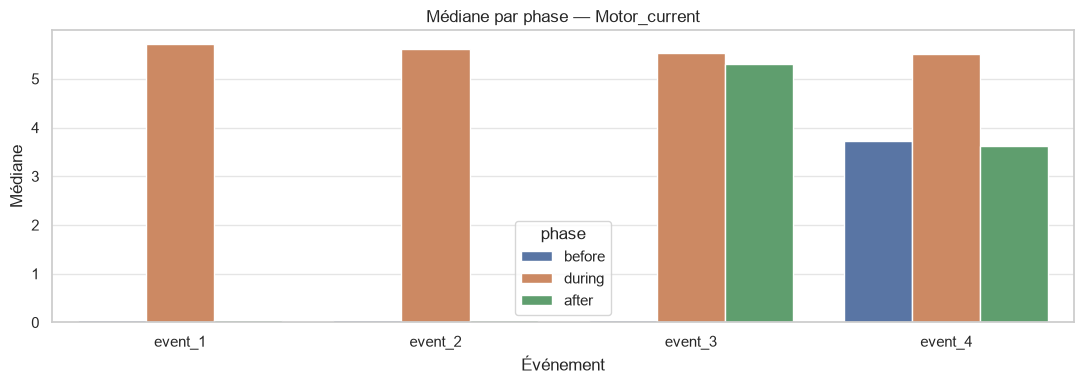

In [23]:
for col in numeric_features:
    subset = phase_stats[phase_stats["feature"] == col]

    plt.figure(figsize=(11, 4))
    sns.barplot(data=subset, x="event", y="median", hue="phase")
    plt.title(f"Médiane par phase — {col}")
    plt.xlabel("Événement")
    plt.ylabel("Médiane")
    plt.tight_layout()
    plt.show()

In [24]:
digital_results = []

for event_name, event in events.items():
    phases = extract_event_phases(df, event)

    for phase_name, phase_data in phases.items():
        for col in digital_features:
            values = phase_data[col].dropna()

            if values.empty:
                continue

            digital_results.append({
                "event": event_name,
                "phase": phase_name,
                "feature": col,
                "count": len(values),
                "activation_rate": values.mean()
            })

digital_phase_stats = pd.DataFrame(digital_results)
display(digital_phase_stats)

,event,phase,feature,count,activation_rate
0,event_1,before,COMP,6301,0.834947
1,event_1,before,DV_eletric,6301,0.023806
2,event_1,before,Towers,6301,0.846850
3,event_1,before,MPG,6301,0.834947
4,event_1,before,LPS,6301,0.002539
...,...,...,...,...,...
91,event_4,after,MPG,8600,0.848721
92,event_4,after,LPS,8600,0.000465
93,event_4,after,Pressure_switch,8600,0.998605
94,event_4,after,Oil_level,8600,0.886279


## 6. Statistiques glissantes et variations

Les statistiques glissantes sont calculées sur des fenêtres temporelles (1 heure et 6 heures). `min_periods` impose un nombre minimal d'observations. Les périodes sans données ne sont pas interpolées.

Ces calculs sont exploratoires. Pour une utilisation prédictive, seules des fenêtres causales (passé et présent, jamais futur) seront autorisées.

In [25]:
rolling_features = {}

for col in numeric_features:
    rolling_features[col] = pd.DataFrame({
        "mean_1h": df[col].rolling("1h", min_periods=30).mean(),
        "std_1h": df[col].rolling("1h", min_periods=30).std(),
        "mean_6h": df[col].rolling("6h", min_periods=100).mean(),
        "std_6h": df[col].rolling("6h", min_periods=100).std(),
    })

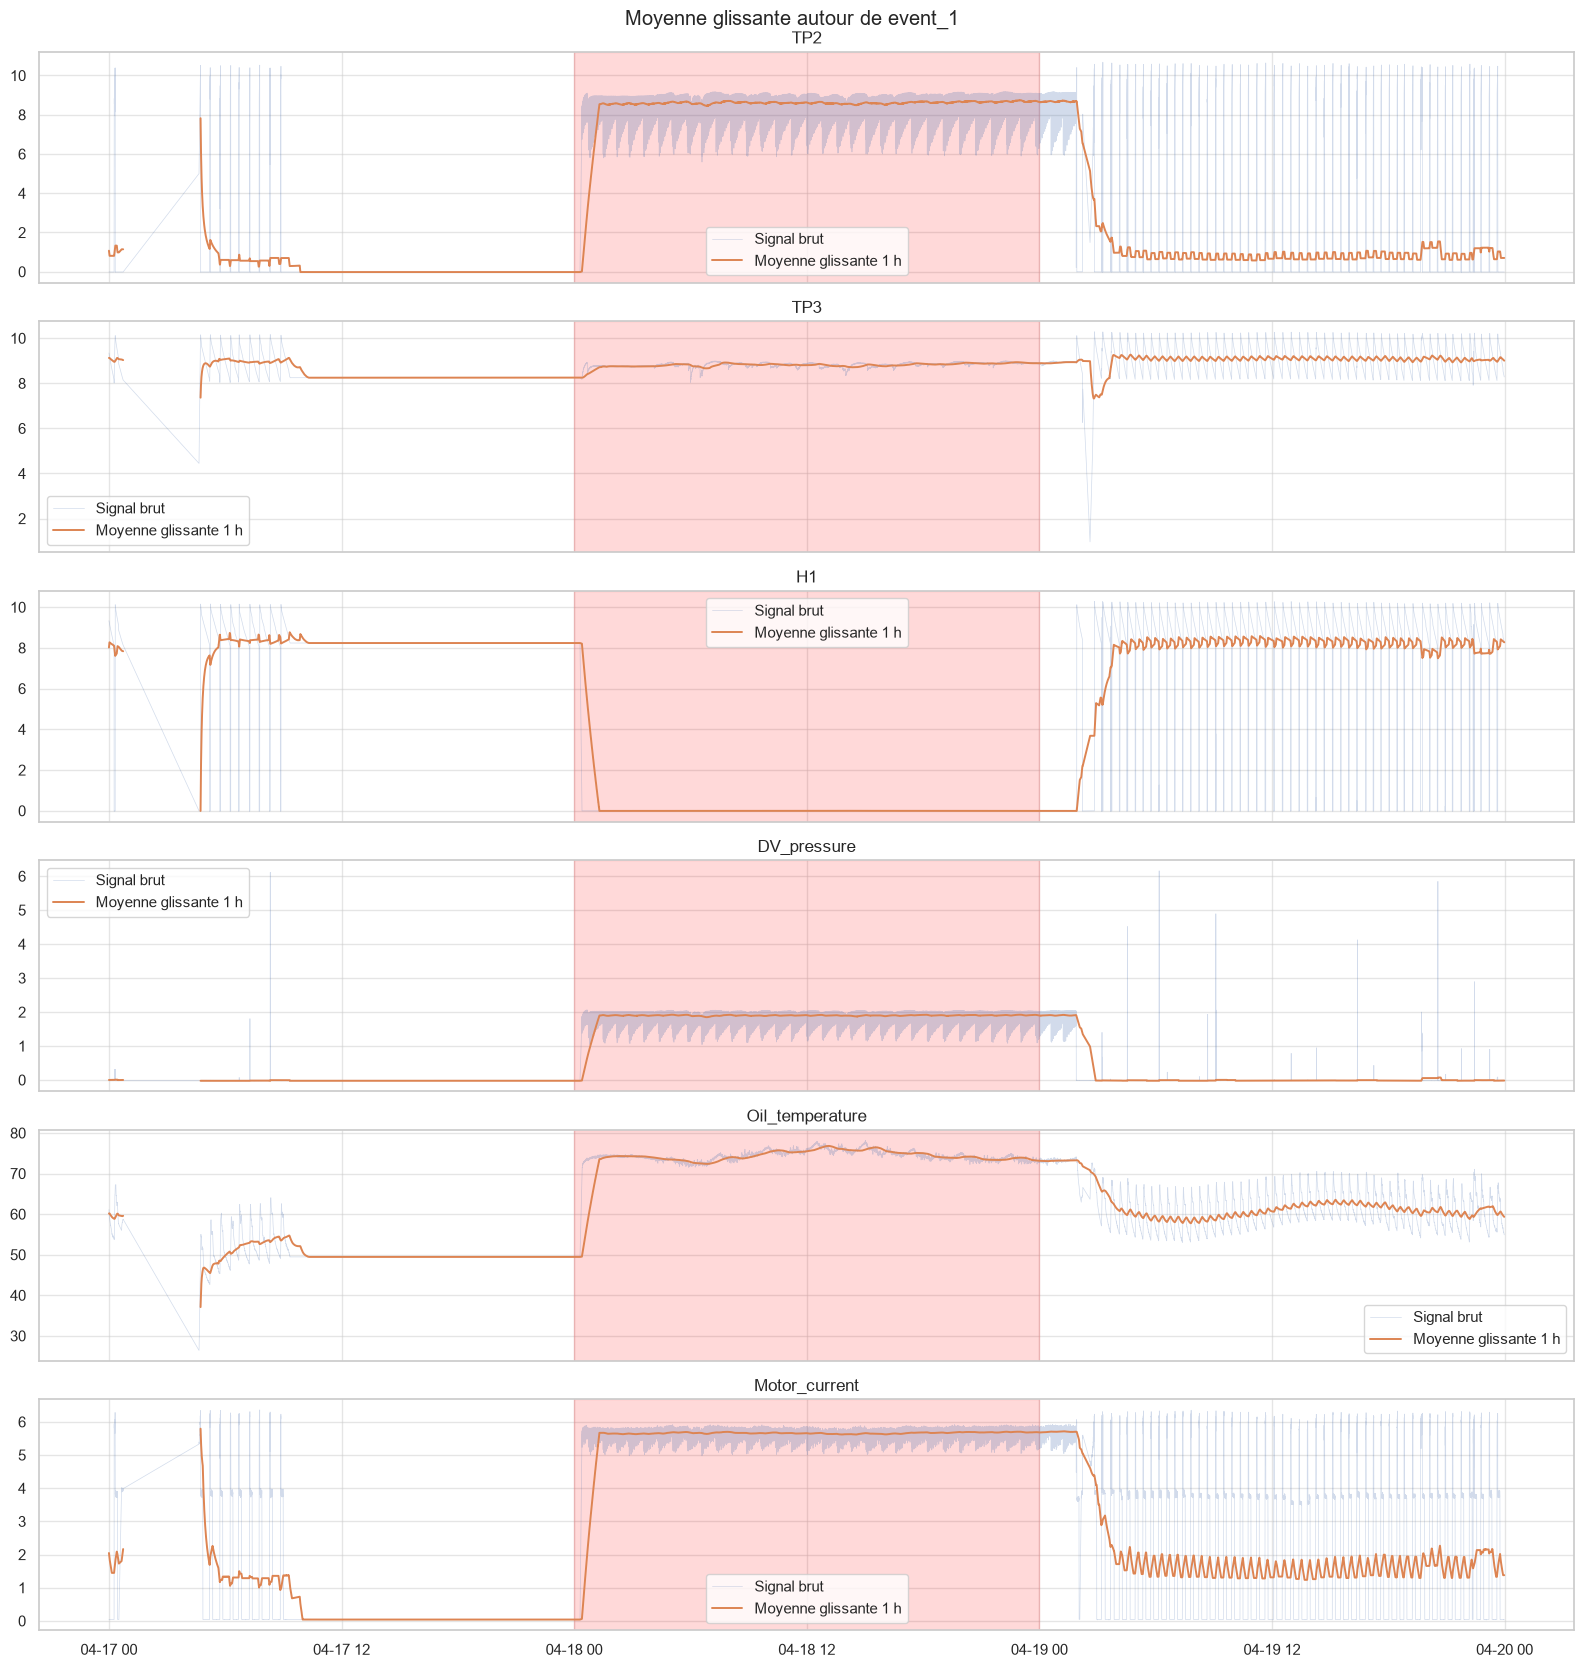

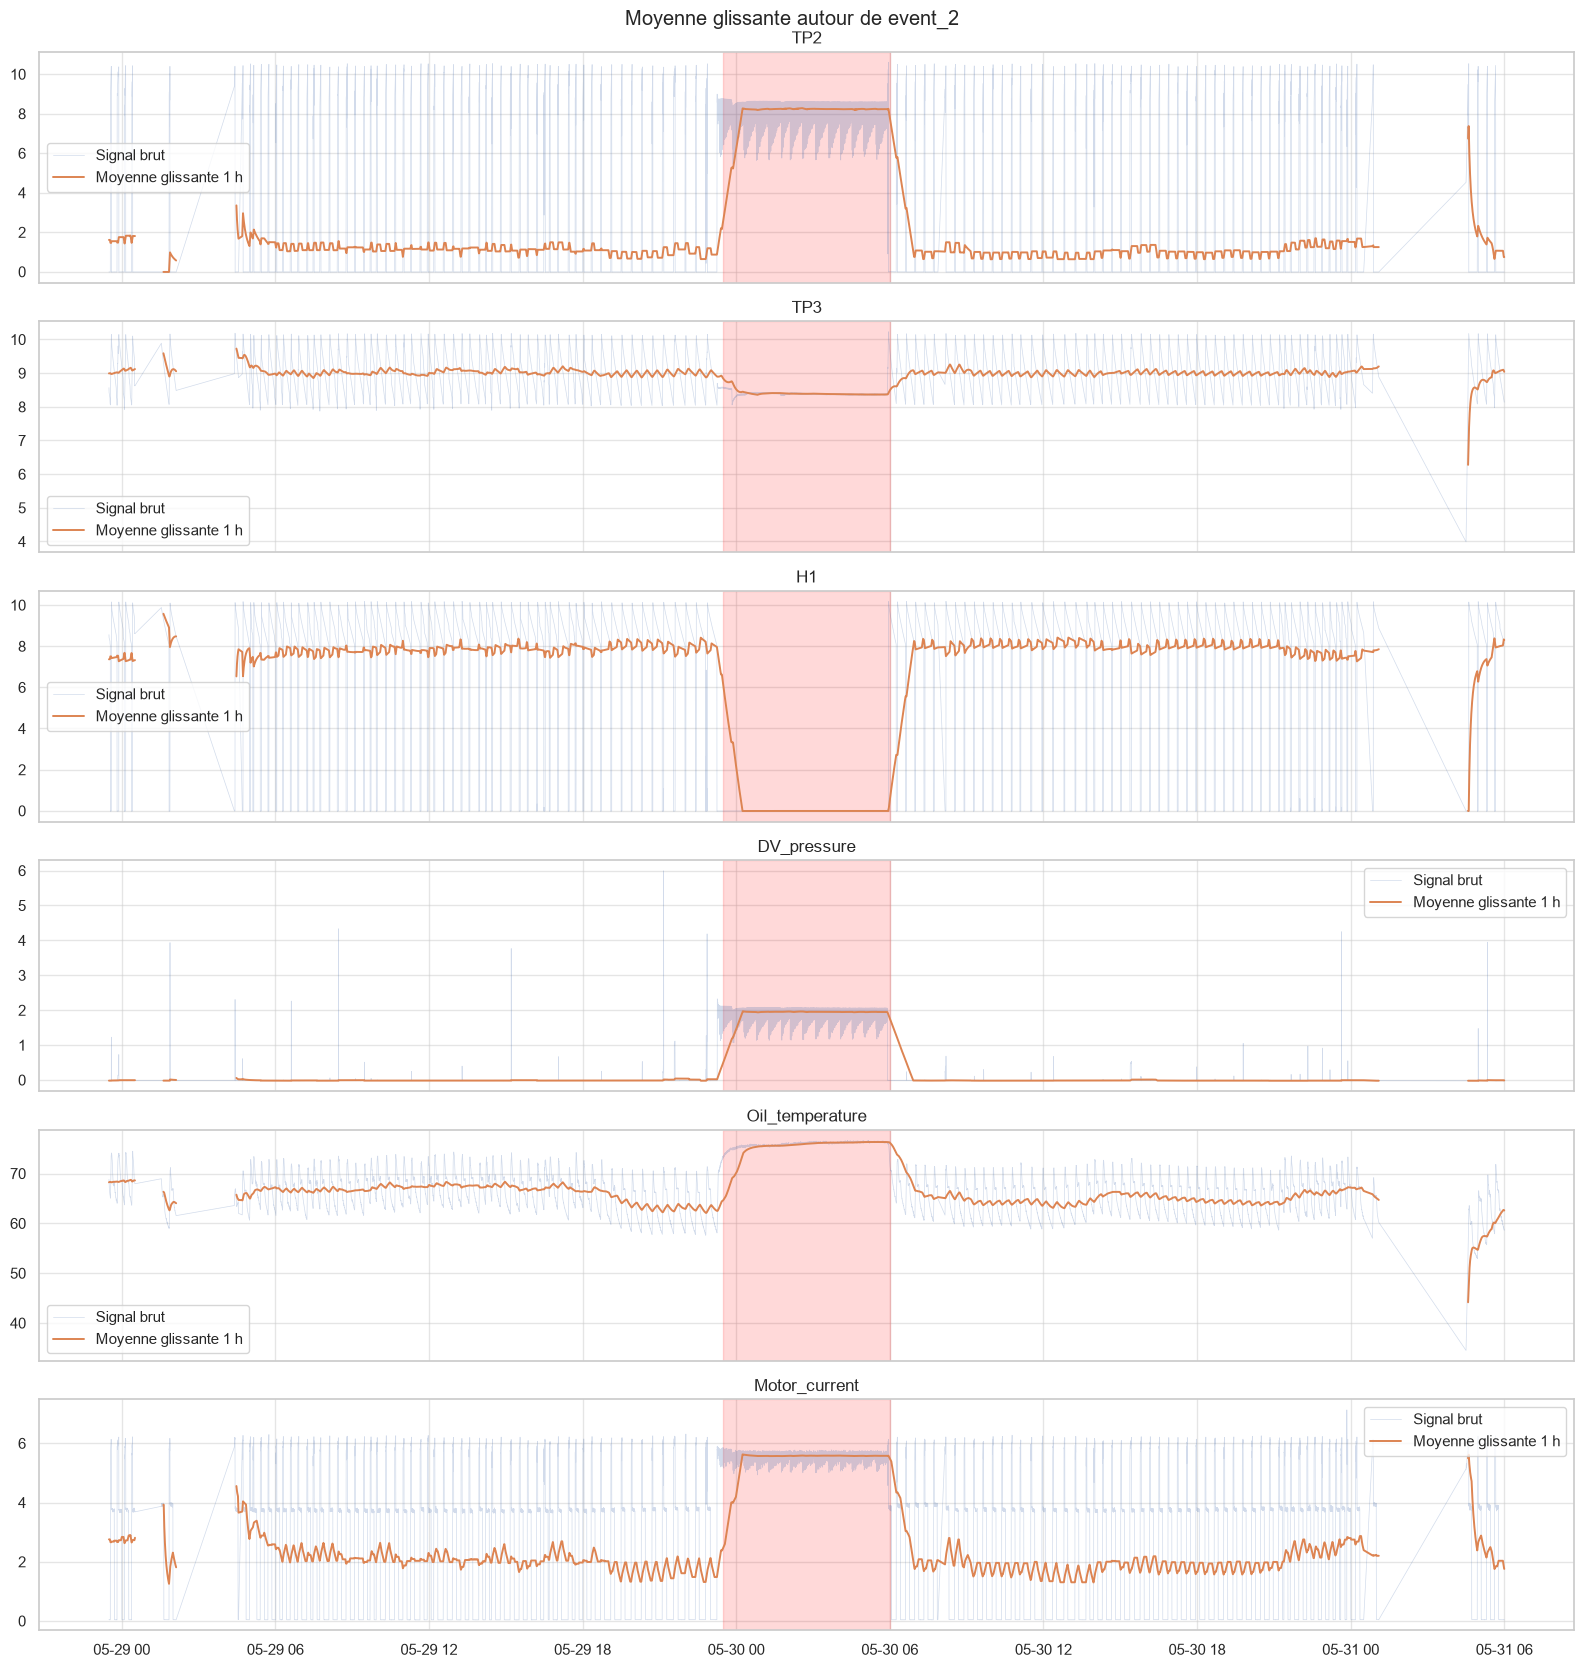

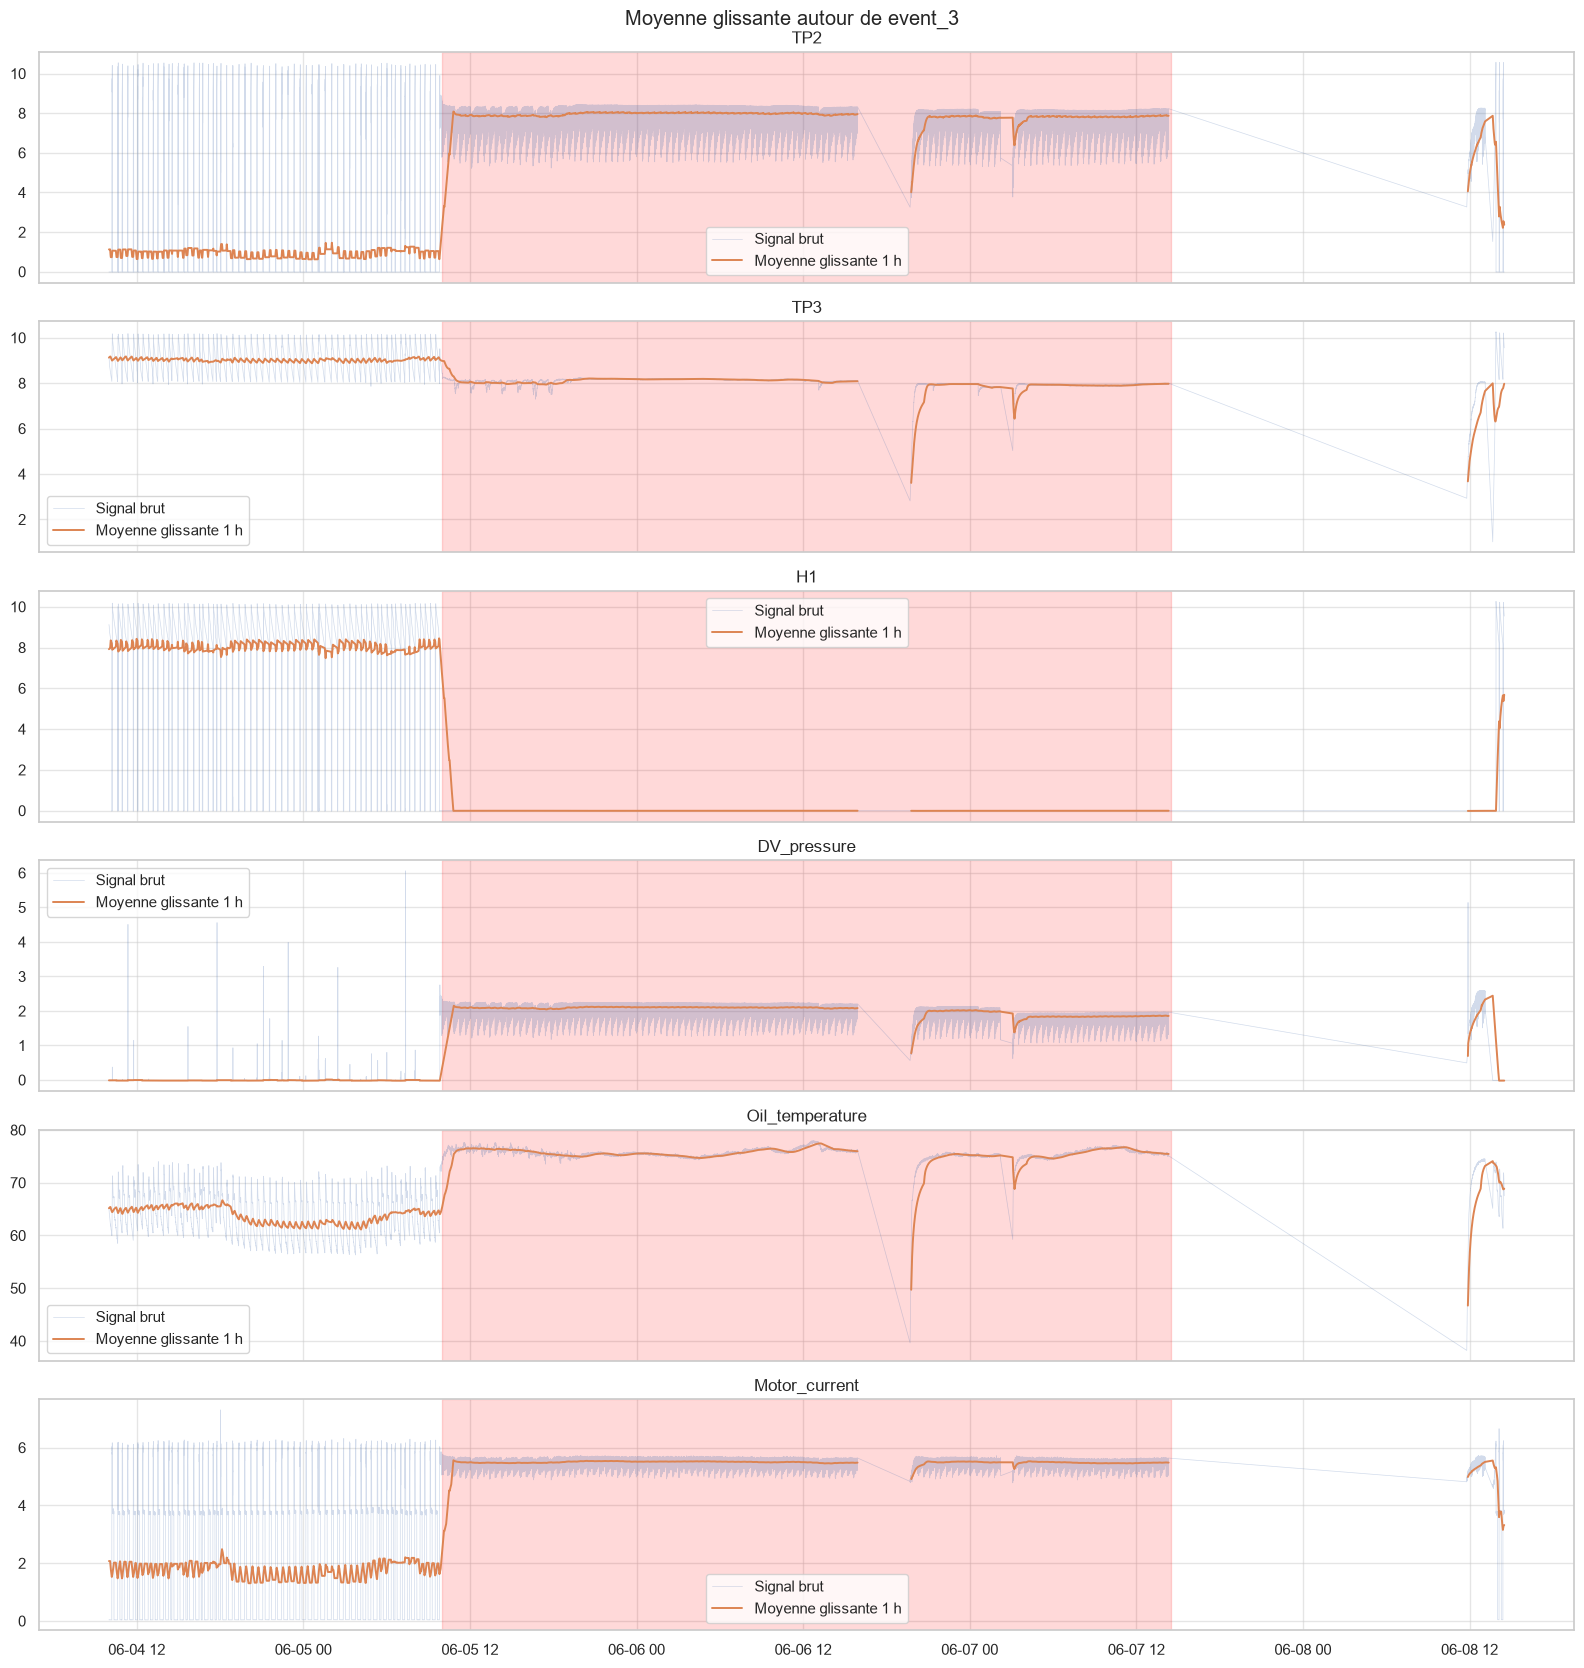

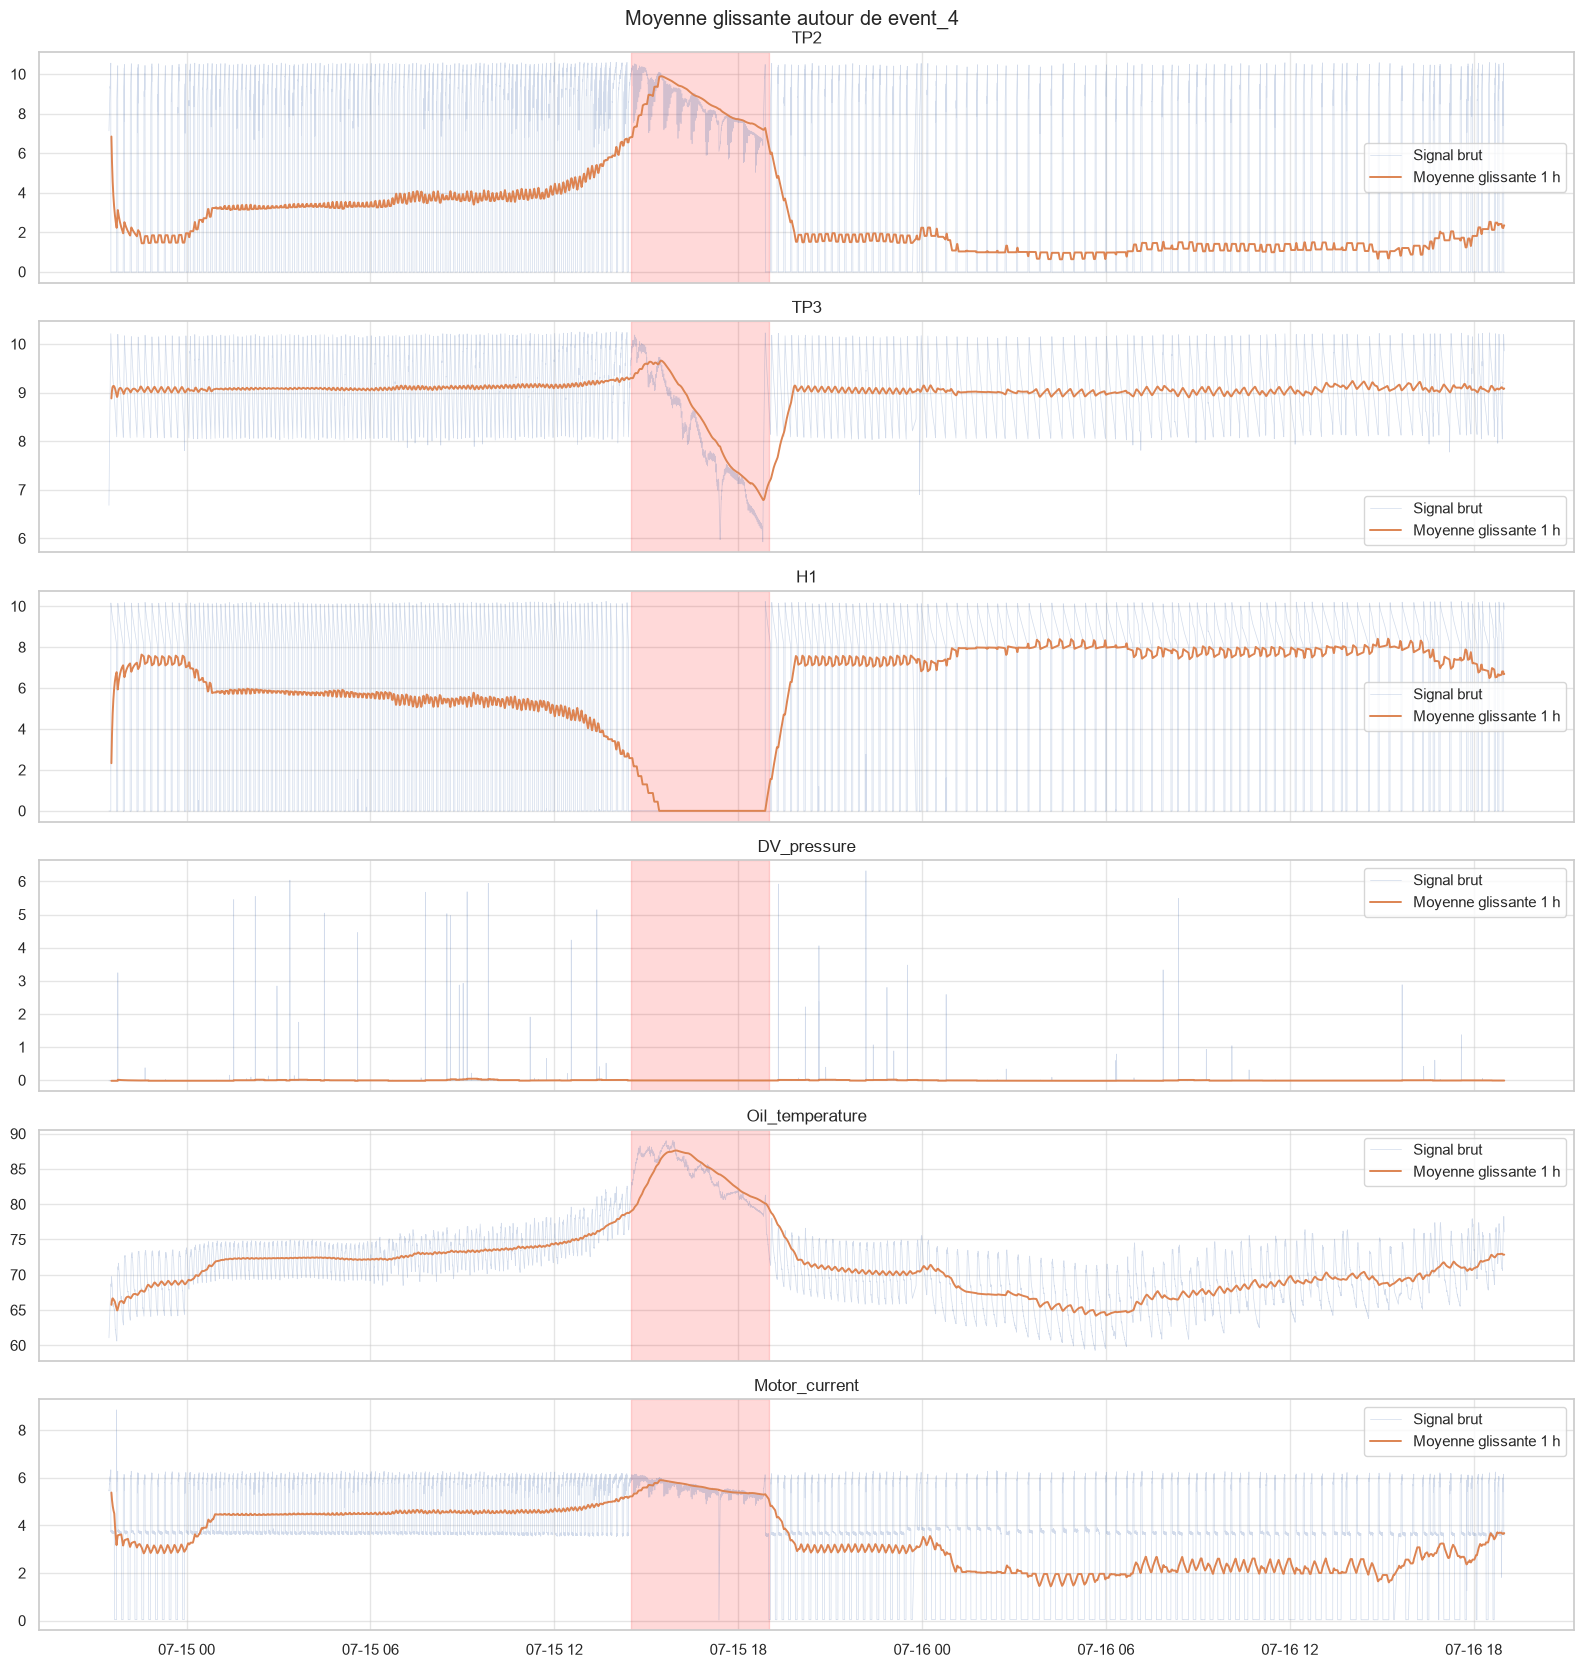

In [26]:
for event_name, event in events.items():
    start, end = event["start"], event["end"]
    window_start = start - WINDOW_BEFORE
    window_end = end + WINDOW_AFTER

    fig, axes = plt.subplots(
        len(selected_numeric), 1,
        figsize=(16, 17), sharex=True
    )

    for ax, col in zip(axes, selected_numeric):
        raw = df.loc[window_start:window_end, col]
        mean_1h = rolling_features[col].loc[
            window_start:window_end, "mean_1h"
        ]

        ax.plot(raw.index, raw, alpha=0.25, linewidth=0.5,
                label="Signal brut")
        ax.plot(mean_1h.index, mean_1h, linewidth=1.4,
                label="Moyenne glissante 1 h")
        ax.axvspan(start, end, color="red", alpha=0.15)
        ax.set_title(col)
        ax.legend()

    fig.suptitle(f"Moyenne glissante autour de {event_name}")
    plt.tight_layout()
    plt.show()

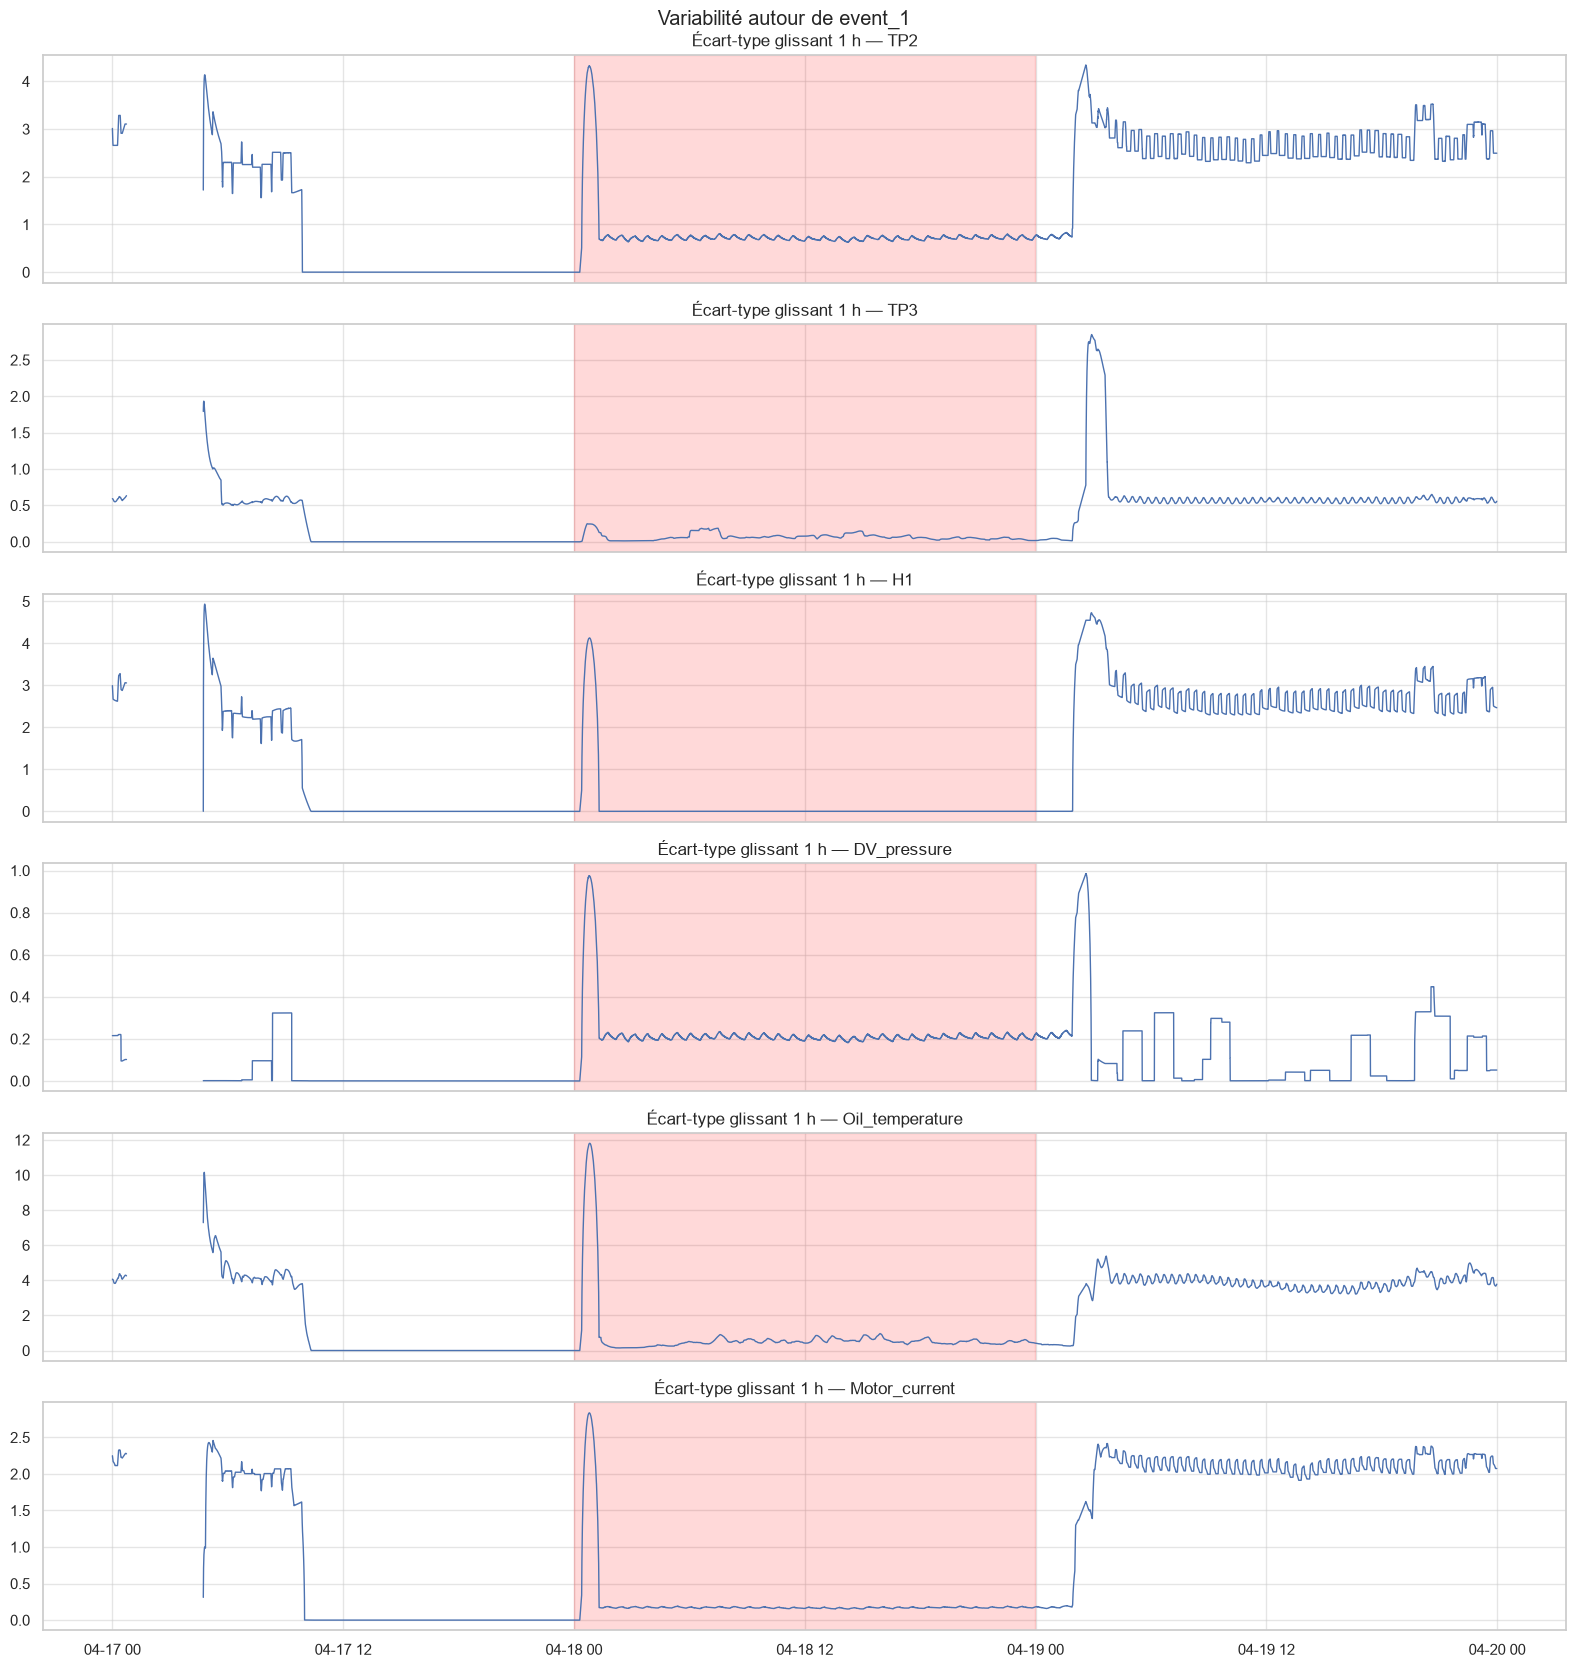

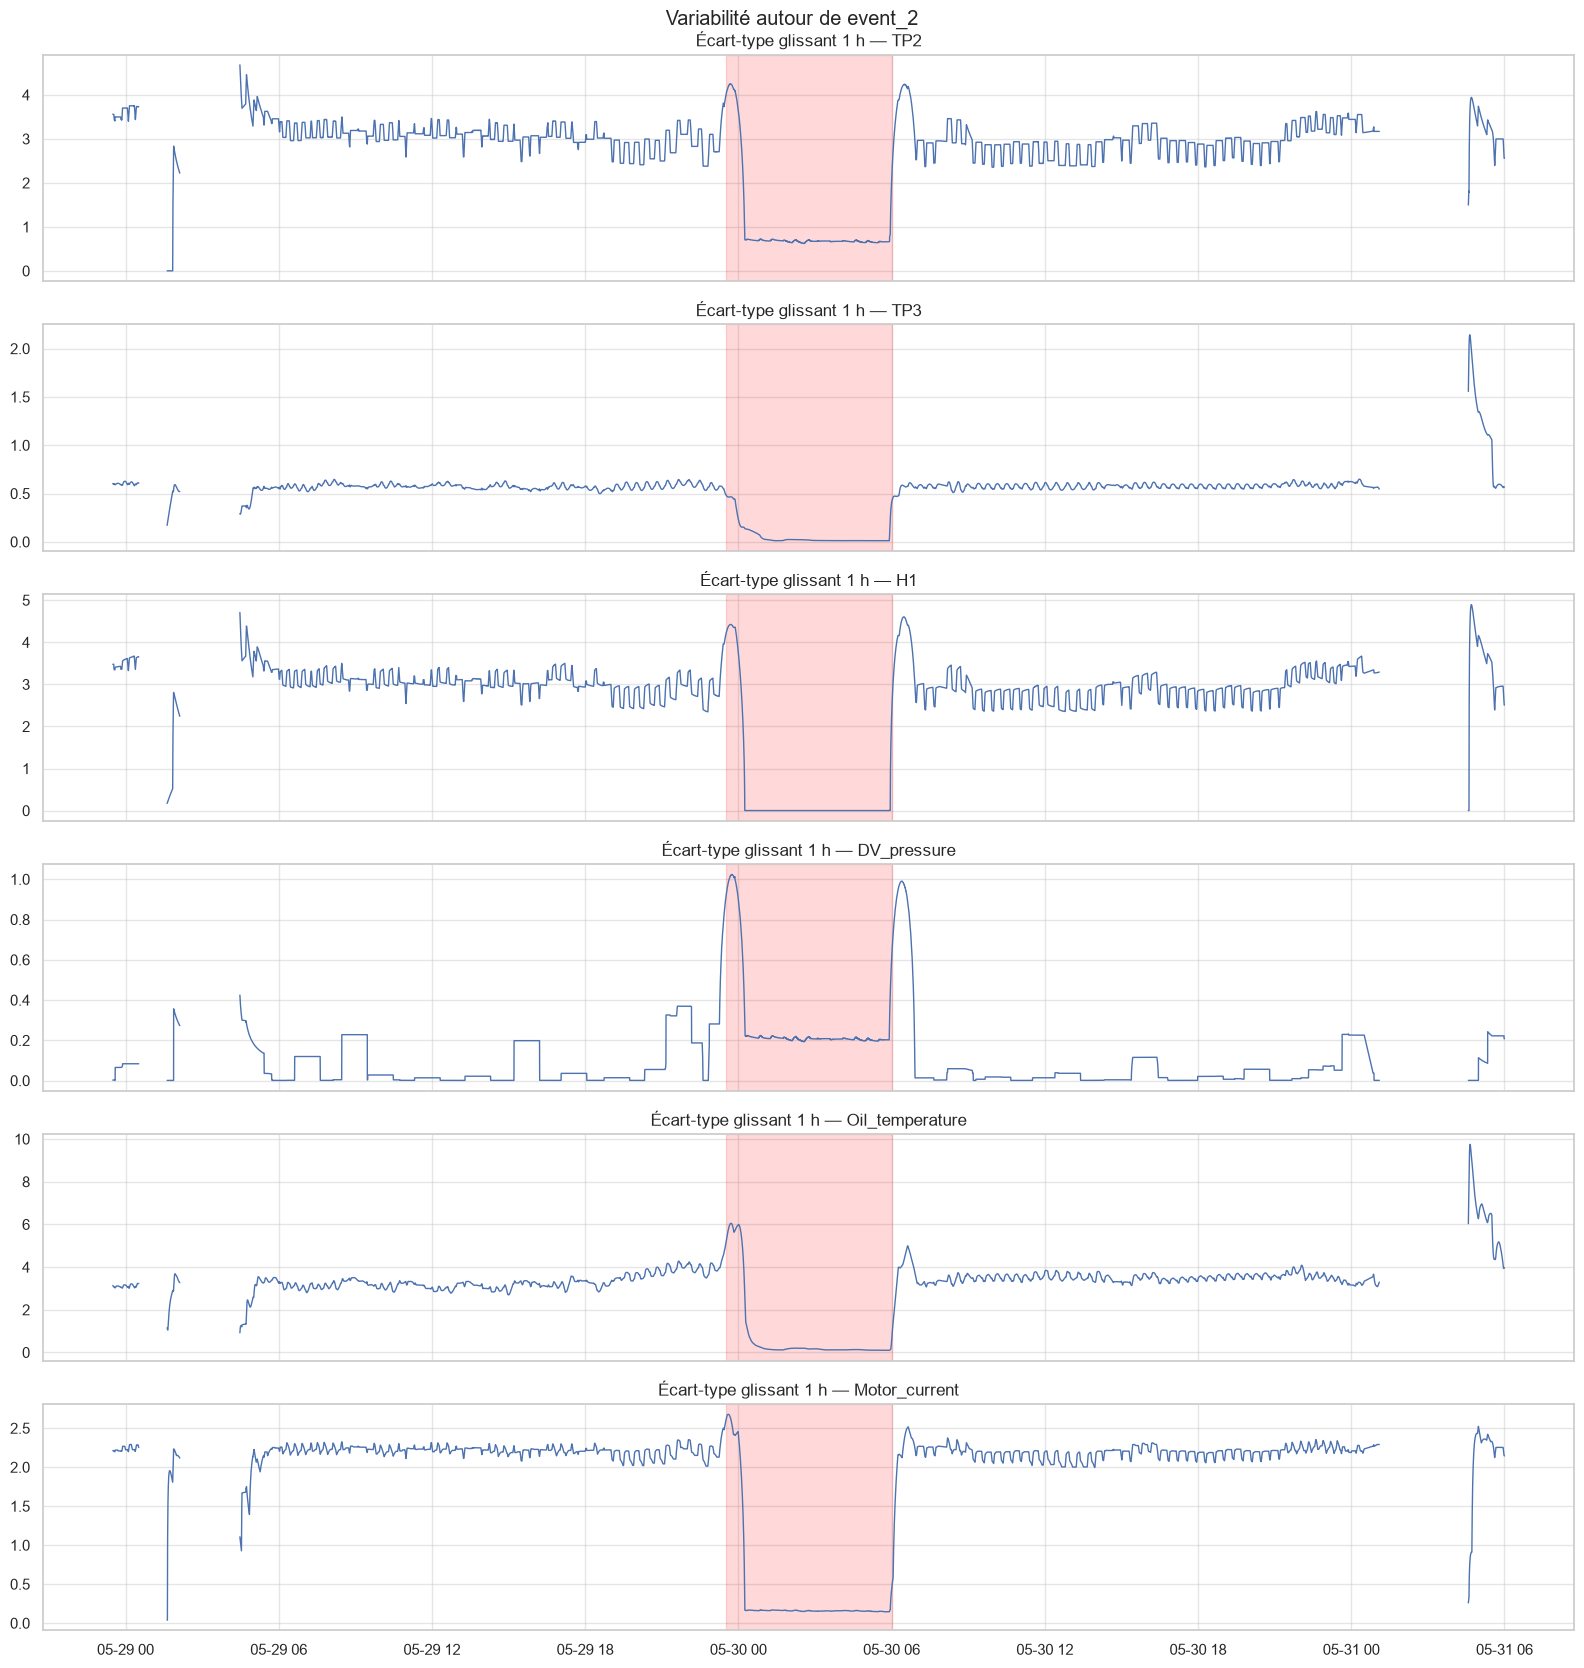

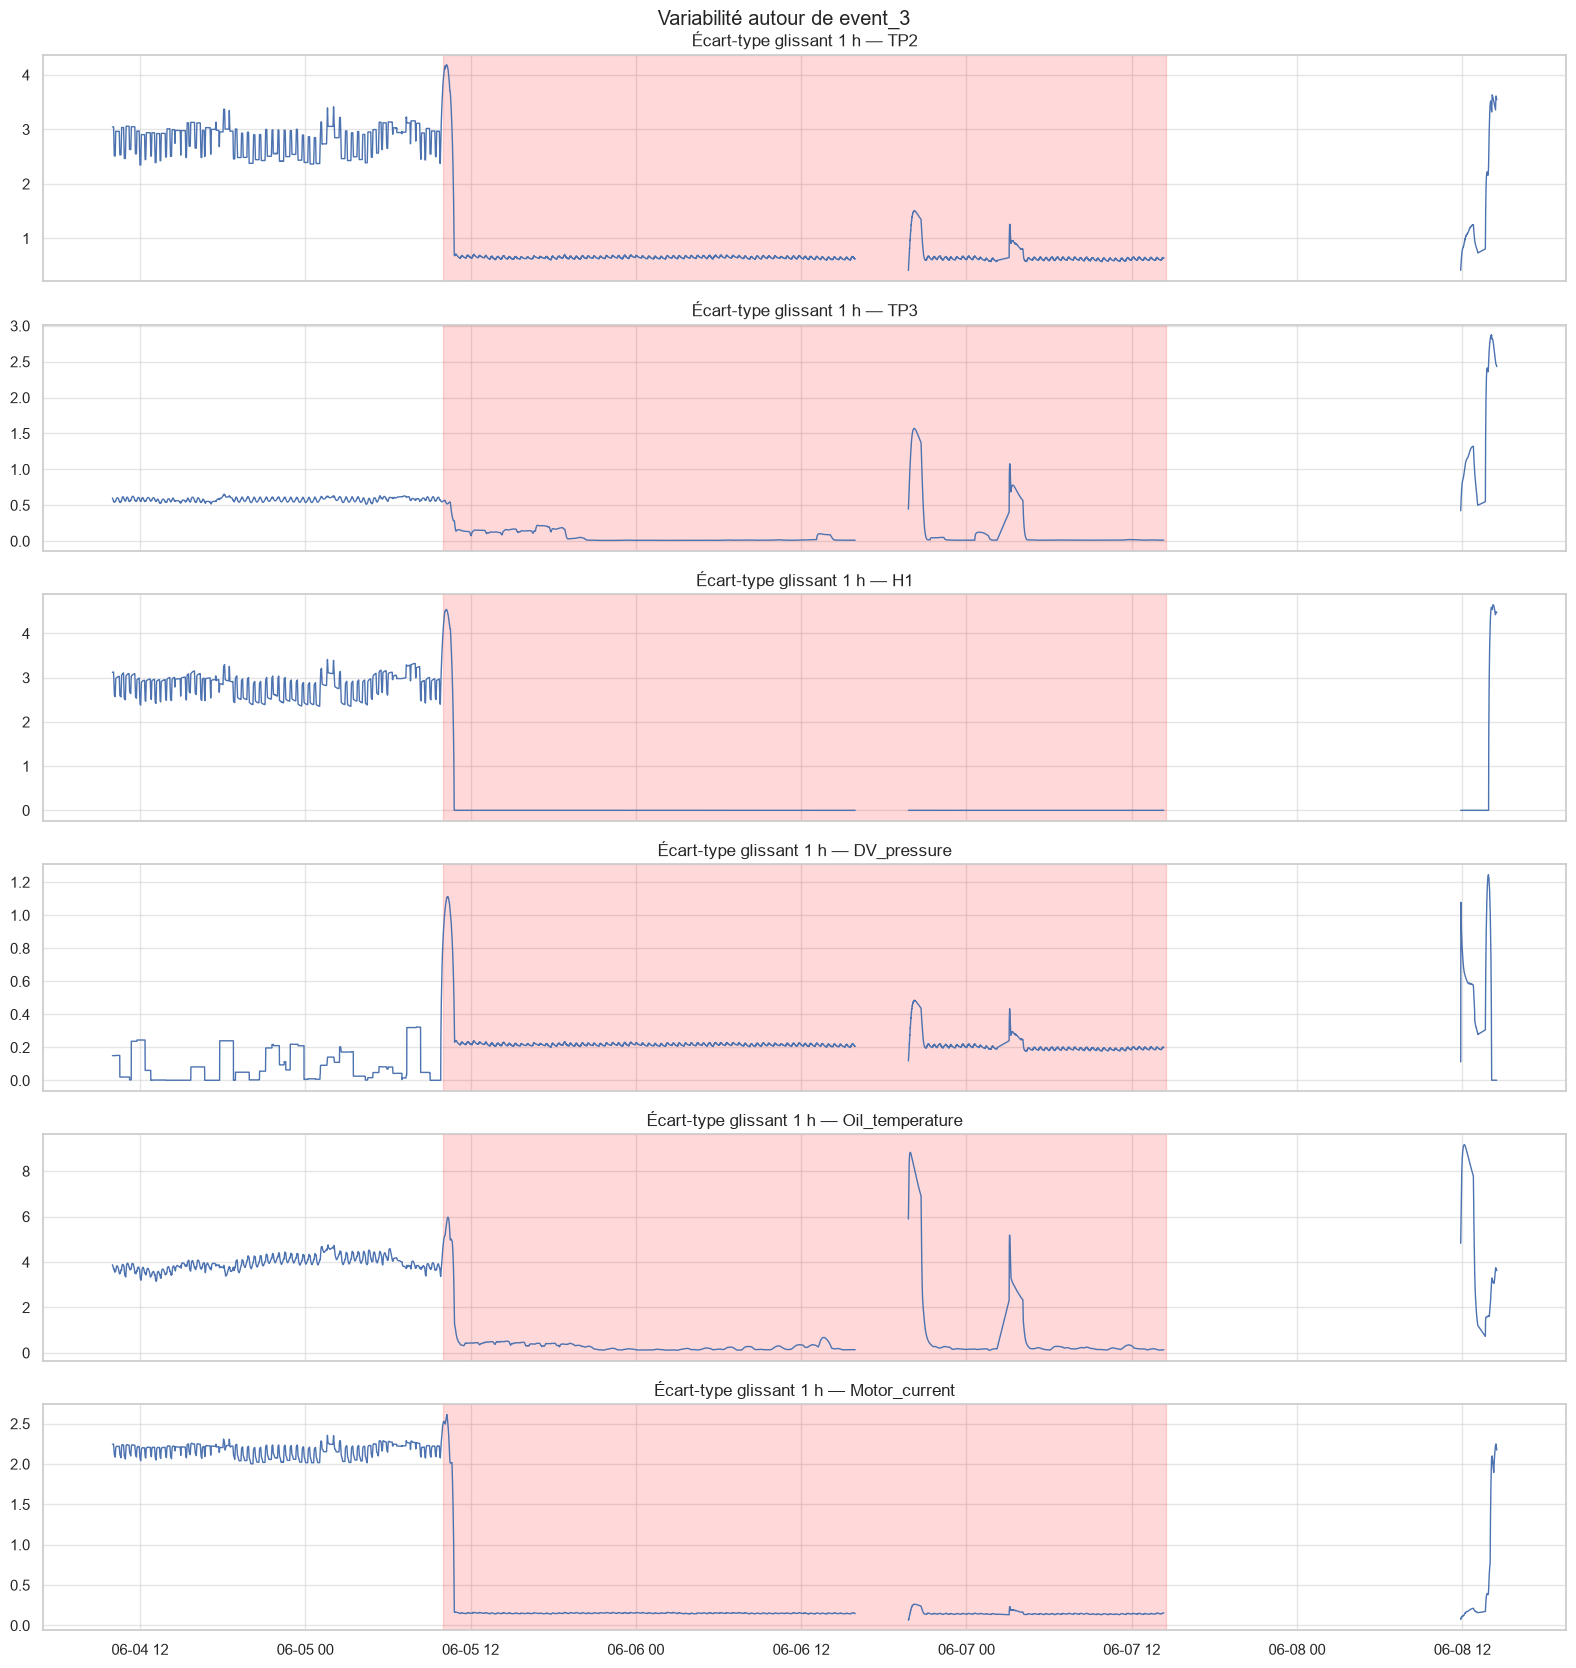

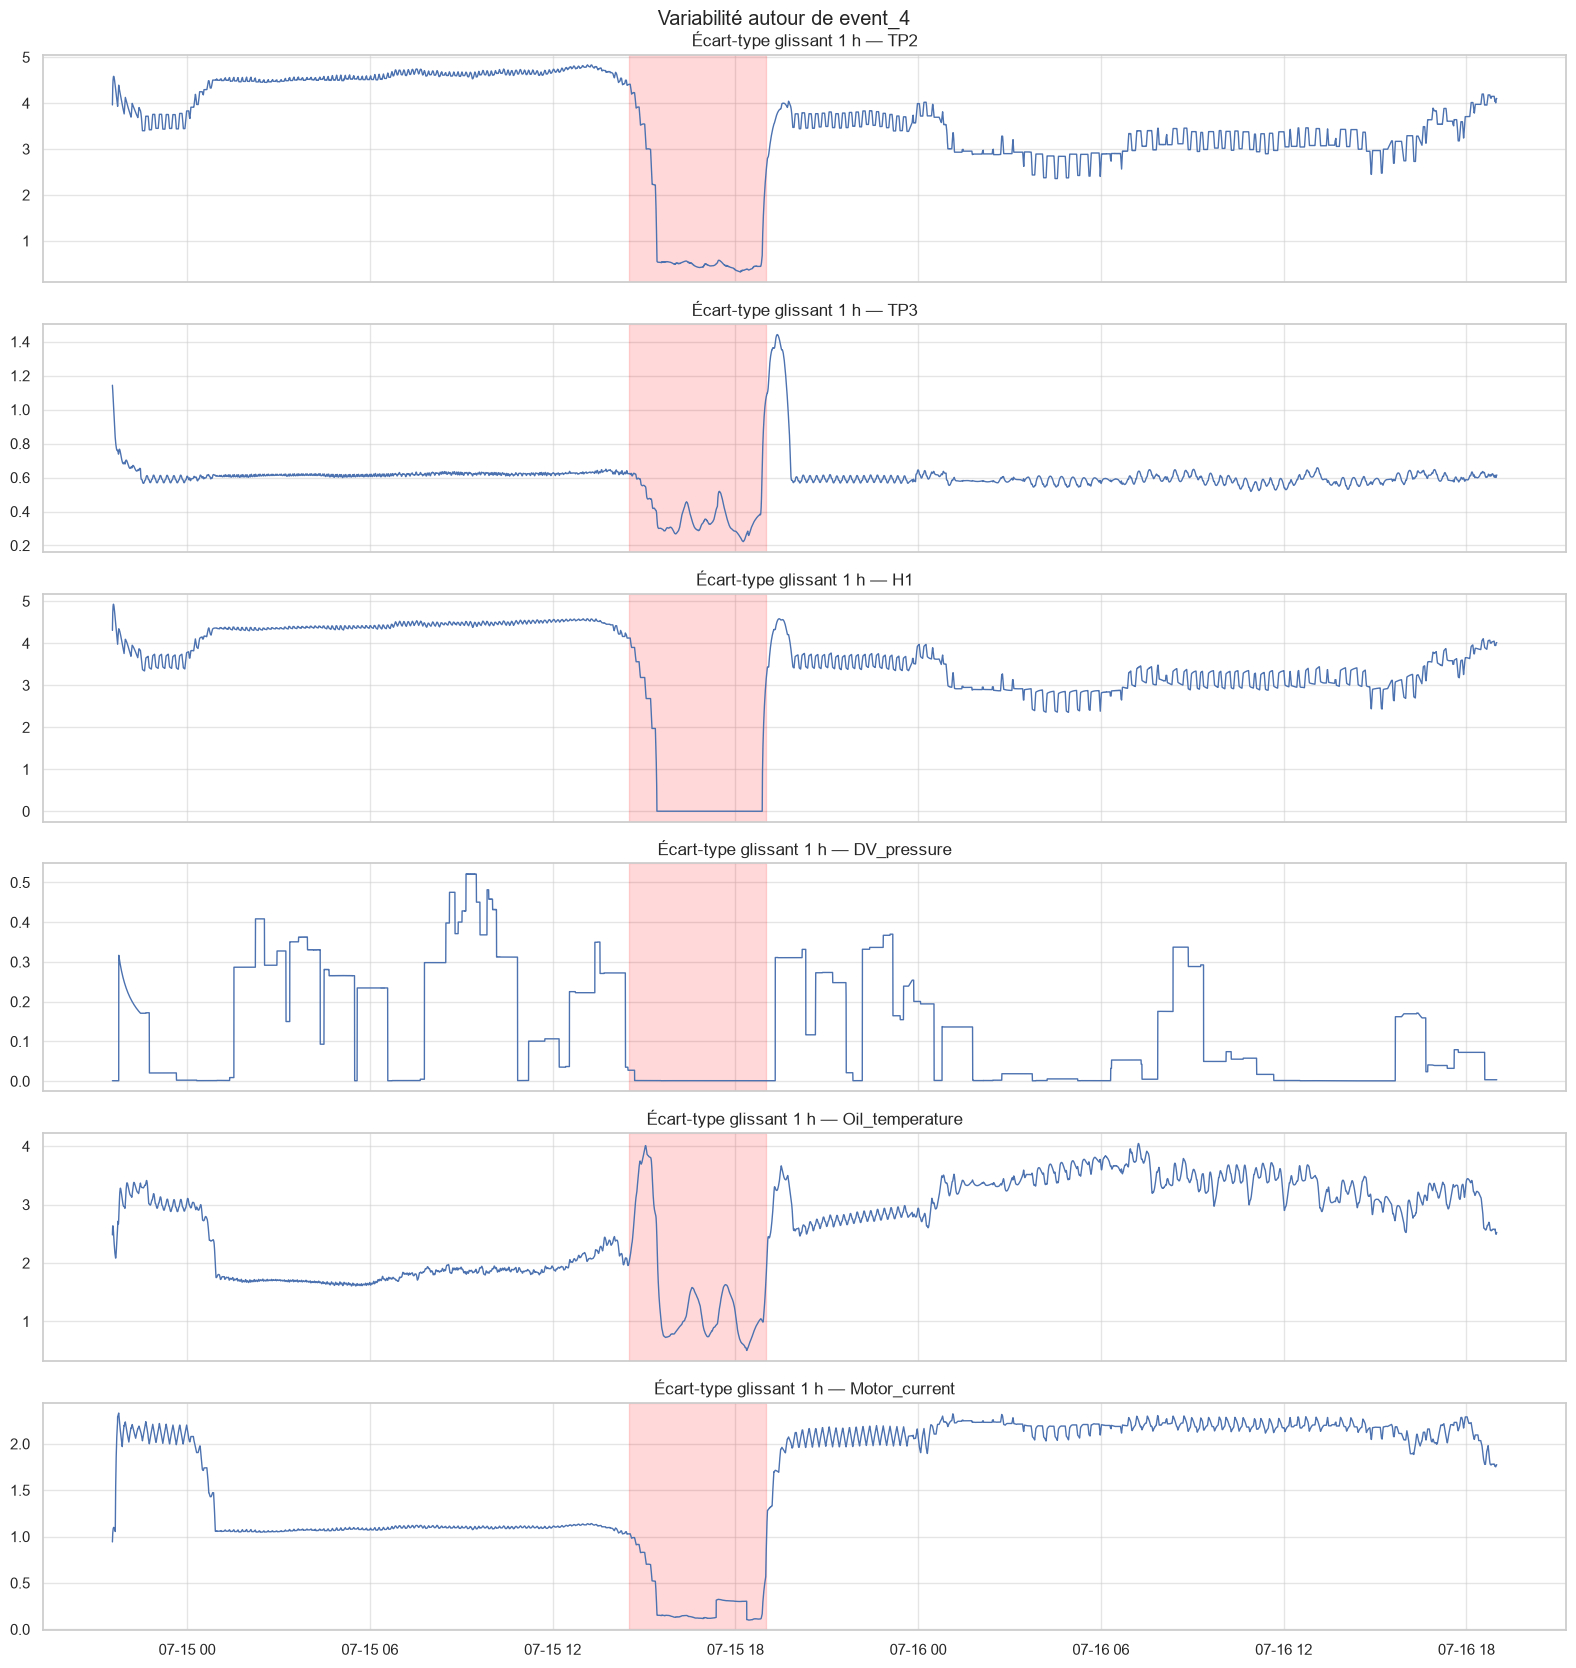

In [27]:
for event_name, event in events.items():
    start, end = event["start"], event["end"]
    window_start = start - WINDOW_BEFORE
    window_end = end + WINDOW_AFTER

    fig, axes = plt.subplots(
        len(selected_numeric), 1,
        figsize=(16, 17), sharex=True
    )

    for ax, col in zip(axes, selected_numeric):
        std_1h = rolling_features[col].loc[
            window_start:window_end, "std_1h"
        ]
        ax.plot(std_1h.index, std_1h, linewidth=1)
        ax.axvspan(start, end, color="red", alpha=0.15)
        ax.set_title(f"Écart-type glissant 1 h — {col}")

    fig.suptitle(f"Variabilité autour de {event_name}")
    plt.tight_layout()
    plt.show()

### 6.1. Variations entre observations successives

Le dataset est irrégulier : une différence entre deux lignes ne correspond pas toujours à la même durée. On conserve donc l'intervalle réel entre les timestamps pour interpréter ces variations.

In [28]:
time_delta_seconds = df.index.to_series().diff().dt.total_seconds()
diff_features = df[numeric_features].diff()

diff_summary = pd.DataFrame({
    "mean_absolute_change": diff_features.abs().mean(),
    "median_absolute_change": diff_features.abs().median(),
    "std_change": diff_features.std(),
    "max_absolute_change": diff_features.abs().max()
})

display(diff_summary)

,mean_absolute_change,median_absolute_change,std_change,max_absolute_change
TP2,0.205440,0.0020,1.099465,10.6960
TP3,0.030874,0.0140,0.073161,8.7100
H1,0.148829,0.0120,1.100610,10.2960
DV_pressure,0.017356,0.0000,0.201032,8.0040
Reservoirs,0.030821,0.0140,0.073121,8.7300
Oil_temperature,0.187457,0.1000,0.388929,54.0250
Motor_current,0.116627,0.0025,0.560530,9.2525


In [29]:
change_interval_results = []

for col in numeric_features:
    temp = pd.DataFrame({
        "interval_seconds": time_delta_seconds,
        "absolute_change": diff_features[col].abs()
    }).dropna()

    change_interval_results.append({
        "feature": col,
        "correlation_interval_change": temp["interval_seconds"].corr(
            temp["absolute_change"]
        ),
        "valid_pairs": len(temp)
    })

change_interval_results = pd.DataFrame(change_interval_results)
display(change_interval_results)

,feature,correlation_interval_change,valid_pairs
0,TP2,0.027334,1516947
1,TP3,0.382129,1516947
2,H1,0.035939,1516947
3,DV_pressure,0.003658,1516947
4,Reservoirs,0.382835,1516947
5,Oil_temperature,0.433671,1516947
6,Motor_current,0.042463,1516947


## 7. Comparaison entre les événements

Cette section rassemble les résultats par événement. Les événements n'ont pas la même durée : les statistiques de la phase `during` doivent être interprétées en tenant compte de cette différence.

In [30]:
numeric_comparison = phase_stats.pivot_table(
    index=["event", "feature"],
    columns="phase",
    values="median"
)

display(numeric_comparison)

phase                      after   before   during
event   feature                                   
event_1 DV_pressure      -0.0220  -0.0240   2.0000
        H1                8.8420   8.2380  -0.0080
        Motor_current     0.0450   0.0400   5.7075
        Oil_temperature  60.7750  49.4500  74.2250
        Reservoirs        8.9800   8.2480   8.8360
        TP2              -0.0120  -0.0180   8.9320
        TP3               8.9780   8.2480   8.8340
event_2 DV_pressure      -0.0200  -0.0180   2.0500
        H1                8.8380   8.8180  -0.0080
        Motor_current     0.0425   0.0450   5.6125
        Oil_temperature  64.3250  66.3250  76.0750
        Reservoirs        9.0040   8.9930   8.3800
        TP2              -0.0120  -0.0100   8.5560
        TP3               9.0020   8.9920   8.3780
event_3 DV_pressure       1.6930  -0.0200   2.1040
        H1               -0.0080   8.8440  -0.0080
        Motor_current     5.2950   0.0450   5.5275
        Oil_temperature  71.9500  63.2250  75.5500
        Reservoirs        8.0130   9.0040   8.0820
        TP2               6.5030  -0.0120   8.1460
        TP3               8.0100   9.0020   8.0780
event_4 DV_pressure      -0.0140  -0.0180  -0.0080
        H1                8.8130   8.4140  -0.0020
        Motor_current     3.6150   3.7175   5.5150
        Oil_temperature  68.9250  73.0250  84.6000
        Reservoirs        9.0300   9.1100   8.2150
        TP2              -0.0100  -0.0100   8.3680
        TP3               9.0280   9.1080   8.2160

In [31]:
digital_comparison = digital_phase_stats.pivot_table(
    index=["event", "feature"],
    columns="phase",
    values="activation_rate"
)

display(digital_comparison)

phase                       after    before    during
event   feature                                      
event_1 COMP             0.824313  0.834947  0.008201
        Caudal_impulses  1.000000  0.858753  0.997690
        DV_eletric       0.175687  0.023806  0.989488
        LPS              0.008416  0.002539  0.000000
        MPG              0.824313  0.834947  0.008201
        Oil_level        1.000000  0.858753  0.997690
        Pressure_switch  0.998130  0.858435  0.991683
        Towers           0.912683  0.846850  0.501213
event_2 COMP             0.881891  0.861104  0.008051
        Caudal_impulses  1.000000  1.000000  1.000000
        DV_eletric       0.118109  0.139030  0.991949
        LPS              0.003170  0.000000  0.000000
        MPG              0.881891  0.861104  0.008051
        Oil_level        1.000000  1.000000  1.000000
        Pressure_switch  0.999173  0.998661  0.995339
        Towers           0.940877  0.930485  0.504237
event_3 COMP             0.239130  0.887219  0.000000
        Caudal_impulses  1.000000  1.000000  1.000000
        DV_eletric       0.760870  0.112781  1.000000
        LPS              0.398977  0.000000  0.011435
        MPG              0.239130  0.887219  0.000000
        Oil_level        1.000000  1.000000  1.000000
        Pressure_switch  0.998721  0.998623  0.995957
        Towers           0.617647  0.943896  0.501126
event_4 COMP             0.848721  0.607437  0.026510
        Caudal_impulses  1.000000  1.000000  1.000000
        DV_eletric       0.151279  0.392563  0.973490
        LPS              0.000465  0.000970  0.326757
        MPG              0.848721  0.607437  0.026510
        Oil_level        0.886279  1.000000  1.000000
        Pressure_switch  0.998605  0.996281  0.996301
        Towers           0.924302  0.804365  0.511714

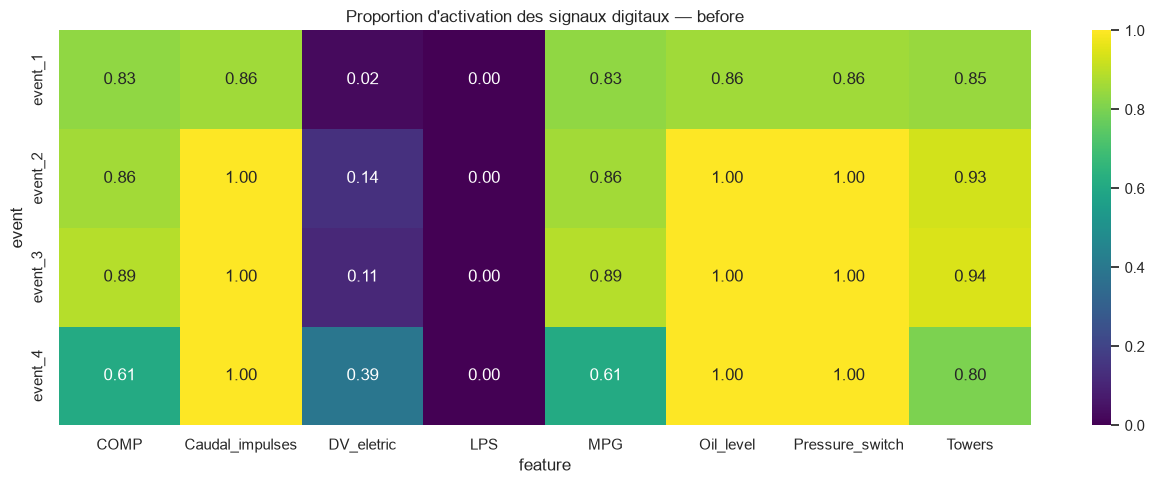

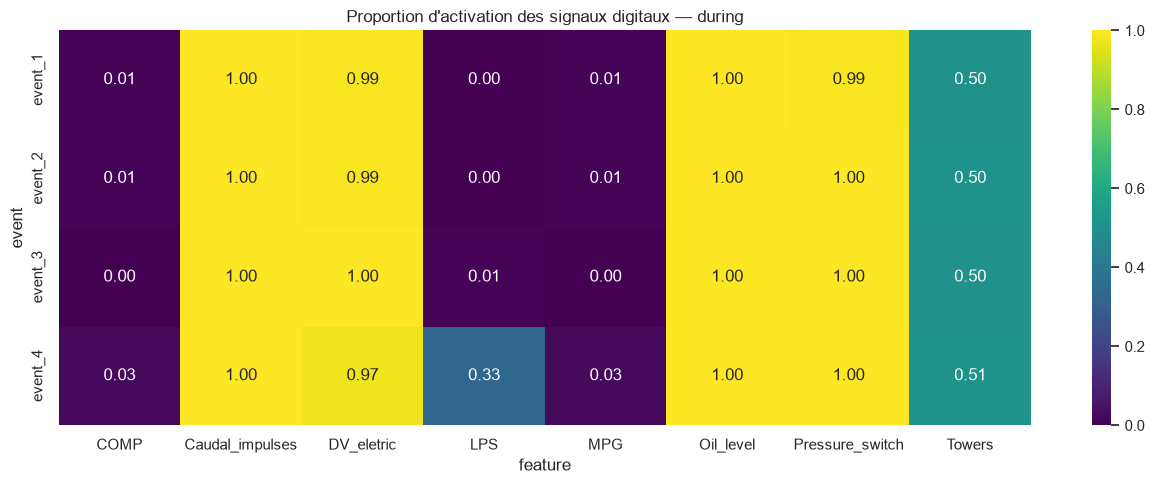

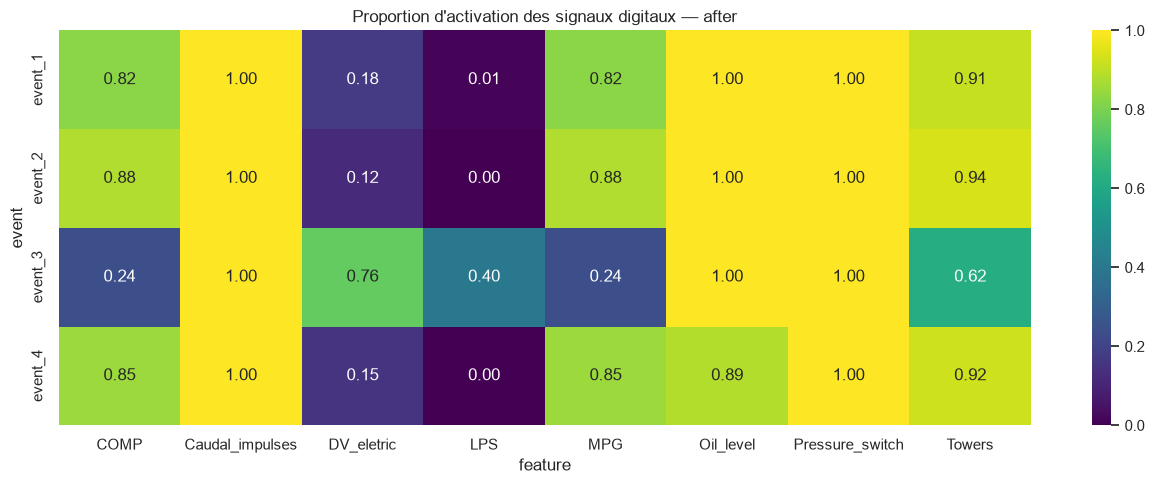

In [32]:
for phase in ["before", "during", "after"]:
    phase_data = digital_phase_stats[
        digital_phase_stats["phase"] == phase
    ]

    pivot = phase_data.pivot(
        index="event", columns="feature", values="activation_rate"
    )

    plt.figure(figsize=(13, 5))
    sns.heatmap(pivot, annot=True, fmt=".2f",
                cmap="viridis", vmin=0, vmax=1)
    plt.title(f"Proportion d'activation des signaux digitaux — {phase}")
    plt.tight_layout()
    plt.show()

In [33]:
numeric_changes = []

for event_name in events:
    for col in numeric_features:
        subset = phase_stats[
            (phase_stats["event"] == event_name) &
            (phase_stats["feature"] == col)
        ].set_index("phase")

        if not {"before", "during"}.issubset(subset.index):
            continue

        before_value = subset.loc["before", "median"]
        during_value = subset.loc["during", "median"]

        numeric_changes.append({
            "event": event_name,
            "feature": col,
            "before_median": before_value,
            "during_median": during_value,
            "absolute_change": during_value - before_value
        })

numeric_changes = pd.DataFrame(numeric_changes)
display(numeric_changes.sort_values(["feature", "event"]))

,event,feature,before_median,during_median,absolute_change
3,event_1,DV_pressure,-0.0240,2.0000,2.0240
10,event_2,DV_pressure,-0.0180,2.0500,2.0680
17,event_3,DV_pressure,-0.0200,2.1040,2.1240
24,event_4,DV_pressure,-0.0180,-0.0080,0.0100
2,event_1,H1,8.2380,-0.0080,-8.2460
9,event_2,H1,8.8180,-0.0080,-8.8260
16,event_3,H1,8.8440,-0.0080,-8.8520
23,event_4,H1,8.4140,-0.0020,-8.4160
6,event_1,Motor_current,0.0400,5.7075,5.6675
13,event_2,Motor_current,0.0450,5.6125,5.5675


## 8. Dépendance temporelle et autocorrélation

Le pas de temps original est irrégulier. Pour exprimer les retards en minutes, on agrège les mesures à une fréquence d'une minute. Les minutes sans mesure restent manquantes : aucune interpolation n'est effectuée.

Les retards sont donc interprétés comme des minutes calendaires après agrégation, et non comme un nombre de lignes du dataset original.

In [34]:
df_1min = df[numeric_features].resample("1min").mean()

print("Dimensions après agrégation :", df_1min.shape)
print("Proportion de minutes manquantes :")
display(df_1min.isna().mean().rename("missing_rate"))

Dimensions après agrégation : (306960, 7)
Proportion de minutes manquantes :


TP2                0.176701
TP3                0.176701
H1                 0.176701
DV_pressure        0.176701
Reservoirs         0.176701
Oil_temperature    0.176701
Motor_current      0.176701
Name: missing_rate, dtype: float64

In [35]:
lags = [1, 5, 10, 30, 60]
autocorr_results = []

for col in numeric_features:
    series = df_1min[col]

    for lag in lags:
        paired = pd.DataFrame({
            "current": series,
            "lagged": series.shift(lag)
        }).dropna()

        corr = (
            paired["current"].corr(paired["lagged"])
            if len(paired) >= 30 else np.nan
        )

        autocorr_results.append({
            "feature": col,
            "lag_minutes": lag,
            "autocorrelation": corr,
            "valid_pairs": len(paired)
        })

autocorr_df = pd.DataFrame(autocorr_results)
display(autocorr_df)

,feature,lag_minutes,autocorrelation,valid_pairs
0,TP2,1,0.733198,252388
1,TP2,5,0.232520,251210
2,TP2,10,0.248172,250168
3,TP2,30,0.314367,247024
4,TP2,60,0.320094,243141
5,TP3,1,0.903094,252388
6,TP3,5,0.170664,251210
7,TP3,10,-0.139167,250168
8,TP3,30,0.176456,247024
9,TP3,60,0.165622,243141


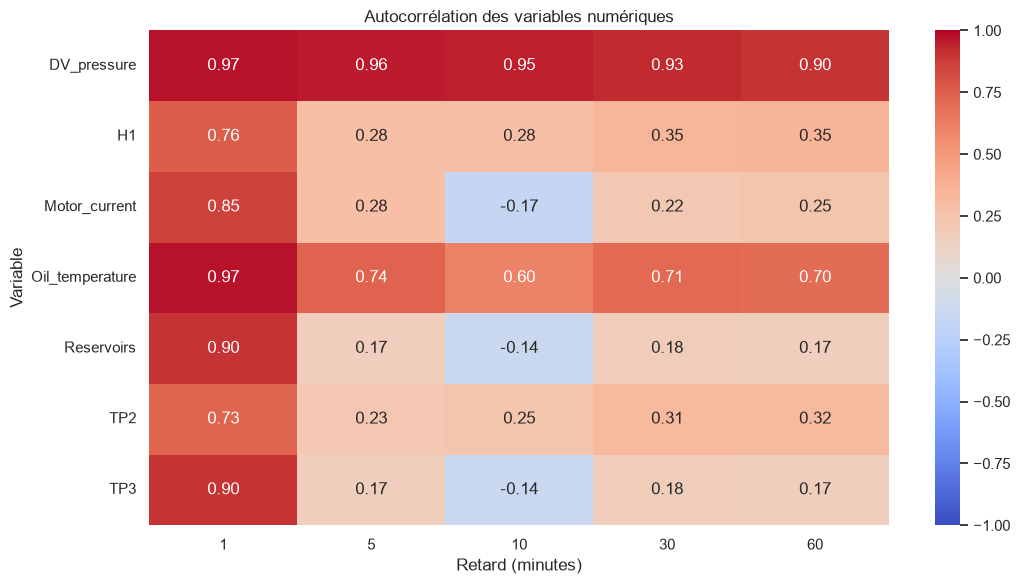

In [36]:
autocorr_pivot = autocorr_df.pivot(
    index="feature",
    columns="lag_minutes",
    values="autocorrelation"
)

plt.figure(figsize=(11, 6))
sns.heatmap(
    autocorr_pivot, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, vmin=-1, vmax=1
)
plt.title("Autocorrélation des variables numériques")
plt.xlabel("Retard (minutes)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

## 9. Synthèse et conclusions

Compléter cette section après exécution du notebook. Ne pas renseigner de résultats supposés.

### 9.1. Comportement temporel global
- Variables numériques : [résultats observés]
- Variables digitales : [résultats observés]
- Périodes présentant des évolutions particulières : [résultats observés]

### 9.2. Comportement autour des événements
- Avant : [résultats observés]
- Pendant : [résultats observés]
- Après : [résultats observés]
- Similarités et différences entre événements : [résultats observés]

### 9.3. Variabilité et dépendance temporelle
- Variables présentant une variabilité notable : [résultats observés]
- Résultats d'autocorrélation : [résultats observés]
- Limites liées aux interruptions de mesure : [à préciser]

### 9.4. Implications pour le Machine Learning
Pistes à évaluer au Notebook 07 :
- moyennes et médianes glissantes ;
- écarts-types glissants ;
- variations et différences temporelles ;
- indicateurs de tendance ;
- indicateurs de changement de régime.

Ces variables ne seront pas ajoutées automatiquement au modèle. Elles devront être construites sans utiliser d'informations futures, puis évaluées expérimentalement par rapport au modèle baseline avec le même protocole de validation.

### 9.5. Conclusion générale
[Écrire ici une conclusion fondée sur les résultats réellement observés.]

## 10. Contrôles avant clôture

- [ ] Le dataset labellisé est chargé correctement.
- [ ] Les timestamps sont convertis et triés.
- [ ] Les quatre intervalles correspondent au Notebook 02 et à `config.yaml`.
- [ ] Les graphiques temporels globaux sont générés.
- [ ] Les quatre événements sont étudiés individuellement.
- [ ] Les phases avant / pendant / après sont comparées.
- [ ] Les statistiques glissantes sont analysées.
- [ ] L'autocorrélation est calculée et interprétée.
- [ ] Les conclusions sont renseignées à partir des résultats réels.

**Limites méthodologiques à retenir**
1. Les statistiques glissantes de ce notebook sont exploratoires. Pour la prédiction, les fenêtres devront être causales.
2. Les interruptions de mesure peuvent affecter les calculs temporels et doivent rester visibles.
3. Les différences entre événements ne démontrent pas à elles seules un changement de mécanisme ou une cause physique.
4. La cible représente les quatre événements documentés ; `target_event = 0` ne prouve pas l'absence de toute anomalie industrielle.